# Winter HAB Analysis: Bloom Patterns of *Heterocapsa triquetra* and *Prorocentrum minimum* in the Chesapeake Bay

This notebook analyzes surface temperature, salinity, and cell count data for two bloom-forming dinoflagellates, *Heterocapsa triquetra* and *Prorocentrum minimum*, from 6 Chesapeake Bay Program (CBP) monitoring locations across the Upper, Middle, and Lower Bay (CB1.1, CB2.2, CB4.3C, CB5.2, WE4.2, and LE5.5/LE5.5-W) from 1984 to 2025.

**Central question:** How do temperature and salinity shape when and where *H. triquetra* and *P. minimum* reach high abundances in the Chesapeake Bay?

1. When and where do the two species occur and bloom? (Part 1)
2. What temperature and salinity conditions are associated with high abundances? (Parts 2 and 3)
3. Can temperature, salinity, and season predict whether each species is present or at high abundance? (Part 4)

**Notebook outline:**
- **Data:** sources and access, compiling the two CBP datasets into one surface dataset, spatial and temporal coverage, data overlap, and environmental conditions (temperature and salinity).
- **Analysis:** Part 1, bloom patterns over time, space, and season; Part 2, temperature and salinity conditions; Part 3, k-means clustering; Part 4, KNN classification; and a summary.

Run the whole notebook from top to bottom (Kernel → Restart & Run All). Loading the two spreadsheets takes a minute or two.

In [1]:
# Import packages and set file locations
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.cluster import KMeans                   # k-means clustering (Part 3)
from sklearn.neighbors import KNeighborsClassifier   # the KNN classifier (Part 4)
from sklearn import metrics                          # accuracy, recall, etc. (Part 4)
from sklearn.model_selection import train_test_split # train/test split (Part 4)
from sklearn.preprocessing import StandardScaler     # scaling (Parts 3 and 4)

pd.set_option('display.max_columns', 30)
plt.rcParams['figure.dpi'] = 110

DATA_DIR = '../Data'
PHYTO_FILE = f'{DATA_DIR}/CompiledPhytoplanktonData.xlsx'
TS_FILE = f'{DATA_DIR}/CompiledTSData.xlsx'
OUT_FILE = f'{DATA_DIR}/hab_surface_compiled.csv'

# Data files are in the Data folder next to this Code folder ('..' means "go up one folder")

# General settings used in figures throughout the notebook
# One color per region, used in every figure so regions are easy to compare
REGION_COLORS = {'Upper Bay': '#1b9e77', 'Middle Bay': '#d95f02', 'Lower Bay': '#7570b3'}

# Station order from north (top of the Bay) to south (Bay mouth), so figures read down the Bay from left to right
STATION_ORDER = ['CB1.1', 'CB2.2', 'CB4.3C', 'CB5.2', 'WE4.2', 'LE5.5', 'LE5.5-W']

MONTH_NAMES = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

## Data Sources and Access

Dataset 1: CBP Phytoplankton Monitoring (taxonomic counts). Phytoplankton species counts from the Chesapeake Bay Program's long-term monitoring program, collected by Maryland DNR (Upper and Middle Bay stations) and Virginia DEQ / Old Dominion University (Lower Bay stations). Samples are composite water samples identified and counted by microscopy; abundance is reported in cells per liter. For this project I use the counts of Heterocapsa triquetra and Prorocentrum minimum. The raw download contains every taxon counted, sampling layer, replicate, method, and station coordinates.

Dataset 2: CBP Tidal Water Quality Monitoring (temperature and salinity). Vertical profiles of water temperature (°C) and salinity (ppt) from the CBP Tidal Water Quality Monitoring program (TWQM, MAIN project), measured with in-situ sondes at fixed depth intervals from the surface to the bottom on each cruise. Only the surface measurement is used here.

Access. Both datasets are public and were downloaded from the Chesapeake Bay Program DataHub, in roughly ten-year blocks per station group, then compiled into one spreadsheet per dataset:

- Plankton data: https://www.chesapeakebay.net/what/downloads/baywide-cbp-plankton-database (DataHub: https://datahub.chesapeakebay.net/LivingResources, Plankton → Phytoplankton → Taxonomic Data)
- Water quality data: https://datahub.chesapeakebay.net/WaterQuality (Tidal Water Quality, MAIN project, parameters WTEMP and SALINITY)

**Stations.** Using 2 stationsfrom each part of the Bay (Upper, Middle, and Lower): CB1.1, CB2.2, CB4.3C, CB5.2, WE4.2, and LE5.5/LE5.5-W (same station, just different names). Originally, three other lower bay stations were downloaded, but their data did not extend the entire time series, so they were later omitted (CB6.1, SBE2, SBE5).

## Compiling the Data

Both files are long-format CBP downloads: one row per measurement. The phytoplankton file has one row per taxon per sample, and the water quality file has one row per parameter (temperature or salinity) per sampling depth.

Remove exact duplicate rows from each raw file.

Keep the six study locations. LE5.5 was relocated and renamed LE5.5-W in 2004, so the six locations are represented by seven station codes. The extra stations in the phytoplankton download (CB6.1, SBE2, SBE5) have no matching temperature/salinity data and are dropped.

Restrict to the surface layer, or as close as possible.

Temperature/salinity: for each station and date, keep the shallowest sampling depth.
Phytoplankton: CBP does not collect true surface phytoplankton samples at most stations. Each sampling event has one near-surface sample, which is either a composite from above the pycnocline (AP), a whole-water-column composite at the shallow Upper Bay stations (WC), or occasionally a true surface sample (S). Keep that one sample and drop the below-pycnocline (BP) samples.

Build species counts. For each sample I take the total H. triquetra and P. minimum abundance (cells/L). If a sample was counted but a species was not recorded, its abundance is set to 0.

Merge on station and date, keeping only dates where both phytoplankton and temperature/salinity data exist.

In [2]:
# Load the two raw compiled datasets (this takes a minute or two)
phyto_raw = pd.read_excel(PHYTO_FILE)
ts_raw = pd.read_excel(TS_FILE)

print('Phytoplankton rows:', len(phyto_raw), '| columns:', phyto_raw.shape[1])
print('Temp/salinity rows:', len(ts_raw), '| columns:', ts_raw.shape[1])
print('Phytoplankton stations:', sorted(phyto_raw['Station'].unique()))
print('Temp/salinity stations:', sorted(ts_raw['Station'].unique()))

Phytoplankton rows: 160892 | columns: 26
Temp/salinity rows: 105306 | columns: 29
Phytoplankton stations: ['CB1.1', 'CB2.2', 'CB4.3C', 'CB5.2', 'CB6.1', 'LE5.5', 'LE5.5-W', 'SBE2', 'SBE5', 'WE4.2']
Temp/salinity stations: ['CB1.1', 'CB2.2', 'CB4.3C', 'CB5.2', 'LE5.5', 'LE5.5-W', 'WE4.2']


In [3]:
# Summarize the size, station coverage, date range, and variables used from each raw dataset.
summary = pd.DataFrame({
    'Raw rows': [len(phyto_raw), len(ts_raw)],
    'Stations in download': [phyto_raw['Station'].nunique(), ts_raw['Station'].nunique()],
    'Start date': [pd.to_datetime(phyto_raw['SampleDate']).min().date(),
                   pd.to_datetime(ts_raw['SampleDate']).min().date()],
    'End date': [pd.to_datetime(phyto_raw['SampleDate']).max().date(),
                 pd.to_datetime(ts_raw['SampleDate']).max().date()],
    'Variables used': ['H. triquetra, P. minimum (cells/L)', 'Temperature (°C), Salinity (ppt)'],
}, index=['Phytoplankton', 'Temperature/Salinity'])
summary

,Raw rows,Stations in download,Start date,End date,Variables used
Phytoplankton,160892,10,1984-08-06,2025-08-29,"H. triquetra, P. minimum (cells/L)"
Temperature/Salinity,105306,7,1984-06-27,2026-06-23,"Temperature (°C), Salinity (ppt)"


In [4]:
# Exact duplicates in the raw files
n_p, n_t = len(phyto_raw), len(ts_raw)
phyto = phyto_raw.drop_duplicates().copy()
ts = ts_raw.drop_duplicates().copy()
print(f'Phytoplankton duplicates removed: {n_p - len(phyto)}')
print(f'Temp/salinity duplicates removed: {n_t - len(ts)}')

# Study stations and regions
REGION = {'CB1.1': 'Upper Bay', 'CB2.2': 'Upper Bay',
          'CB4.3C': 'Middle Bay', 'CB5.2': 'Middle Bay',
          'WE4.2': 'Lower Bay', 'LE5.5': 'Lower Bay', 'LE5.5-W': 'Lower Bay'}
STATIONS = list(REGION)
phyto = phyto[phyto['Station'].isin(STATIONS)]
ts = ts[ts['Station'].isin(STATIONS)]
for d in (phyto, ts):
    d['SampleDate'] = pd.to_datetime(d['SampleDate']).dt.normalize()

Phytoplankton duplicates removed: 0
Temp/salinity duplicates removed: 0


In [5]:
# Temperature and salinity data - only keeping the shallowest measurement per date
ts = ts[ts['Parameter'].isin(['WTEMP', 'SALINITY'])]
min_depth = ts.groupby(['Station', 'SampleDate'])['SampleDepthM'].transform('min')
ts_surf = ts[ts['SampleDepthM'] == min_depth]

ts_wide = (ts_surf
           .pivot_table(index=['Station', 'SampleDate'], columns='Parameter',
                        values='MeasureValue', aggfunc='mean')
           .rename(columns={'WTEMP': 'Temperature_C', 'SALINITY': 'Salinity_ppt'})
           .reset_index())
depths = ts_surf.groupby(['Station', 'SampleDate'])['SampleDepthM'].first().rename('TS_Depth_m')
ts_wide = ts_wide.merge(depths.reset_index(), on=['Station', 'SampleDate'])
ts_wide.columns.name = None

print('Surface T/S station-dates:', len(ts_wide))
print('Surface sampling depths used (m):')
print(ts_wide['TS_Depth_m'].value_counts().sort_index())

Surface T/S station-dates: 3885
Surface sampling depths used (m):
TS_Depth_m
0.0       51
0.2        1
0.5     2695
1.0     1135
1.1        1
2.0        1
10.0       1
Name: count, dtype: int64


In [6]:
# Phytoplankton data - keeping the closest to the surface measurement per date (S > AP > WC; drop BP)
LAYER_PRIORITY = {'S': 0, 'AP': 1, 'WC': 2}
phyto = phyto[phyto['Layer'].isin(LAYER_PRIORITY)].copy()
phyto['layer_rank'] = phyto['Layer'].map(LAYER_PRIORITY)
best = phyto.groupby(['Station', 'SampleDate'])['layer_rank'].transform('min')
phyto_surf = phyto[phyto['layer_rank'] == best]

# One row per sampling event (with station coordinates and the layer used)
events = (phyto_surf.groupby(['Station', 'SampleDate'])
          .agg(Latitude=('Latitude', 'first'), Longitude=('Longitude', 'first'),
               Phyto_Layer=('Layer', 'first'))
          .reset_index())
print('Near-surface phytoplankton events:', len(events))
print(events['Phyto_Layer'].value_counts())

Near-surface phytoplankton events: 2431
Phyto_Layer
AP    1927
WC     502
S        2
Name: count, dtype: int64


In [7]:
# Species abundance per event (cells/L); absent in a counted sample = 0
SPECIES_COLUMNS = {'Heterocapsa triquetra': 'H_triquetra_cells_L',
                   'Prorocentrum minimum': 'P_minimum_cells_L'}
sp = phyto_surf[phyto_surf['ScientificName'].isin(SPECIES_COLUMNS)]

# sum within a replicate (some early records split a species across entries),
# then average across replicates
counts = (sp.groupby(['Station', 'SampleDate', 'SampleReplicate', 'ScientificName'])['MeasureValue'].sum()
            .groupby(['Station', 'SampleDate', 'ScientificName']).mean()
            .unstack('ScientificName')
            .rename(columns=SPECIES_COLUMNS)
            .reset_index())
counts.columns.name = None

phyto_events = events.merge(counts, on=['Station', 'SampleDate'], how='left')
phyto_events[list(SPECIES_COLUMNS.values())] = phyto_events[list(SPECIES_COLUMNS.values())].fillna(0)
phyto_events.head()

,Station,SampleDate,Latitude,Longitude,Phyto_Layer,H_triquetra_cells_L,P_minimum_cells_L
0,CB1.1,1984-08-07,39.54794,-76.08481,AP,0.0,0.0
1,CB1.1,1984-09-12,39.54794,-76.08481,AP,0.0,0.0
2,CB1.1,1984-09-26,39.54794,-76.08481,AP,0.0,0.0
3,CB1.1,1984-10-10,39.54794,-76.08481,AP,0.0,0.0
4,CB1.1,1984-11-07,39.54794,-76.08481,AP,0.0,0.0


In [8]:
# Merge, keeping only dates with both datasets
df = phyto_events.merge(ts_wide, on=['Station', 'SampleDate'], how='inner')
df = df.dropna(subset=['Temperature_C', 'Salinity_ppt'], how='all')

df['Region'] = df['Station'].map(REGION)
df['Year'] = df['SampleDate'].dt.year
df['Month'] = df['SampleDate'].dt.month
df['Season'] = df['Month'].map({12: 'Winter', 1: 'Winter', 2: 'Winter',
                                3: 'Spring', 4: 'Spring', 5: 'Spring',
                                6: 'Summer', 7: 'Summer', 8: 'Summer',
                                9: 'Fall', 10: 'Fall', 11: 'Fall'})

cols = ['Station', 'Region', 'Latitude', 'Longitude', 'SampleDate', 'Year', 'Month', 'Season',
        'Temperature_C', 'Salinity_ppt', 'TS_Depth_m', 'Phyto_Layer',
        'H_triquetra_cells_L', 'P_minimum_cells_L']
df = df[cols].sort_values(['Station', 'SampleDate']).reset_index(drop=True)

print(f'Phytoplankton events: {len(phyto_events)} | Surface T/S events: {len(ts_wide)} | '
      f'Matched (both): {len(df)}')

# Check for duplicates one more time
print('Duplicate station-dates in final table:', df.duplicated(['Station', 'SampleDate']).sum())
print('Fully duplicated rows in final table:', df.duplicated().sum())

df.to_csv(OUT_FILE, index=False)
print('Saved', OUT_FILE)
df.head()

Phytoplankton events: 2431 | Surface T/S events: 3885 | Matched (both): 2272
Duplicate station-dates in final table: 0
Fully duplicated rows in final table: 0
Saved ../Data/hab_surface_compiled.csv


,Station,Region,Latitude,Longitude,SampleDate,Year,Month,Season,Temperature_C,Salinity_ppt,TS_Depth_m,Phyto_Layer,H_triquetra_cells_L,P_minimum_cells_L
0,CB1.1,Upper Bay,39.54794,-76.08481,1984-08-07,1984,8,Summer,27.9,0.0,0.5,AP,0.0,0.0
1,CB1.1,Upper Bay,39.54794,-76.08481,1984-09-12,1984,9,Fall,24.1,0.0,0.5,AP,0.0,0.0
2,CB1.1,Upper Bay,39.54794,-76.08481,1984-09-26,1984,9,Fall,22.8,0.0,0.5,AP,0.0,0.0
3,CB1.1,Upper Bay,39.54794,-76.08481,1984-10-10,1984,10,Fall,17.8,0.0,0.5,AP,0.0,0.0
4,CB1.1,Upper Bay,39.54794,-76.08481,1984-11-07,1984,11,Fall,15.7,0.0,0.5,AP,0.0,0.0


In [9]:
# Summary statistics of the compiled surface dataset
df.describe().round(2)

,Latitude,Longitude,SampleDate,Year,Month,Temperature_C,Salinity_ppt,TS_Depth_m,H_triquetra_cells_L,P_minimum_cells_L
count,2272.00,2272.00,2272,2272.00,2272.00,2270.00,2264.00,2272.00,2272.00,2272.00
mean,38.24,-76.28,2001-02-23 01:55:21.126760,2000.64,6.70,17.77,11.75,0.67,17213.22,106769.24
min,37.00,-76.43,1984-08-06 00:00:00,1984.00,1.00,-0.10,0.00,0.00,0.00,0.00
25%,37.24,-76.39,1991-04-01 18:00:00,1991.00,4.00,10.76,3.95,0.50,0.00,0.00
50%,38.14,-76.30,1999-07-19 12:00:00,1999.00,7.00,19.29,13.33,0.50,0.00,1152.00
75%,39.35,-76.18,2009-06-16 06:00:00,2009.00,9.00,25.30,18.14,1.00,0.00,48596.00
max,39.55,-76.08,2025-08-29 00:00:00,2025.00,12.00,30.50,27.82,1.10,2955264.00,9331867.00
std,0.93,0.11,NaN,11.36,2.95,8.09,7.78,0.24,111015.20,420316.67


## Spatial and Temporal Coverage

### Spatial bounds and resolution

Both datasets come from the same fixed CBP monitoring stations, so their spatial resolution is a set of individual points rather than a grid. The six locations span the length of the Bay, from the Susquehanna Flats (CB1.1) to the mouth of the Bay near the Elizabeth River (LE5.5/LE5.5-W). Vertically, the temperature and salinity data are resolved to individual depths (roughly every 1–2 m), while the phytoplankton data are composites over the upper water column.

In [10]:
# List coordinates, date range, and number of matched dates for each station.
stations = (df.groupby(['Station', 'Region'])
              .agg(Latitude=('Latitude', 'first'), Longitude=('Longitude', 'first'),
                   First=('SampleDate', 'min'), Last=('SampleDate', 'max'),
                   Matched_dates=('SampleDate', 'count'))
              .reset_index())
stations['First'] = stations['First'].dt.date
stations['Last'] = stations['Last'].dt.date

print(f"Latitude range:  {df['Latitude'].min():.3f} to {df['Latitude'].max():.3f} °N")
print(f"Longitude range: {df['Longitude'].min():.3f} to {df['Longitude'].max():.3f} °E")
stations

Latitude range:  36.997 to 39.548 °N
Longitude range: -76.428 to -76.085 °E


,Station,Region,Latitude,Longitude,First,Last,Matched_dates
0,CB1.1,Upper Bay,39.54794,-76.08481,1984-08-07,2019-11-20,238
1,CB2.2,Upper Bay,39.34873,-76.17579,1984-08-07,2019-11-20,421
2,CB4.3C,Middle Bay,38.55505,-76.42794,1984-08-06,2019-12-12,434
3,CB5.2,Middle Bay,38.13705,-76.22787,1984-08-06,2019-12-13,407
4,LE5.5,Lower Bay,36.99681,-76.30300,1985-07-08,1996-08-28,169
5,LE5.5-W,Lower Bay,36.99903,-76.31328,2004-03-24,2025-08-29,236
6,WE4.2,Lower Bay,37.24181,-76.38634,1985-08-07,2025-08-29,367


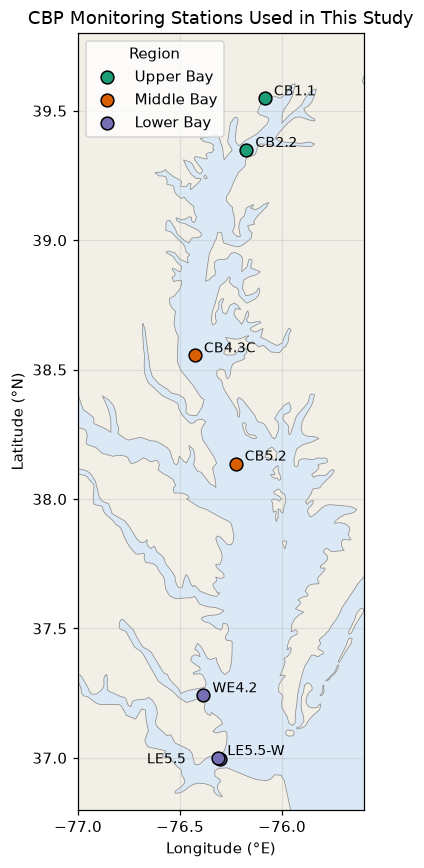

In [11]:
# FIGURE 1: Map of the 7 station codes in the Bay, with the coastline
# The land outline comes from Natural Earth (public domain, 10 m resolution land polygons,
# https://www.naturalearthdata.com), clipped to the Chesapeake Bay area and saved in the Data folder
# as chesapeake_land.geojson. A geojson file is a text file of longitude/latitude points, so it can be
# read with Python's built-in json package and drawn with matplotlib (no extra mapping packages needed).
import json

with open(f'{DATA_DIR}/chesapeake_land.geojson') as f:
    land = json.load(f)

fig, ax = plt.subplots(figsize=(6, 8))
ax.set_facecolor('#dbe9f6')      # light blue background = water

# Draw each land polygon. A "Polygon" is one shape; a "MultiPolygon" is a list of shapes.
# The first ring of each polygon is its outer edge, which is what we fill in.
for feature in land['features']:
    geom = feature['geometry']
    polygons = [geom['coordinates']] if geom['type'] == 'Polygon' else geom['coordinates']
    for polygon in polygons:
        outer_edge = np.array(polygon[0])     # columns: longitude, latitude
        ax.fill(outer_edge[:, 0], outer_edge[:, 1], color='#f2efe6', edgecolor='#8c8c8c',
                linewidth=0.5, zorder=1)

# Stations, colored by region
for region, color in REGION_COLORS.items():
    g = stations[stations['Region'] == region]
    ax.scatter(g['Longitude'], g['Latitude'], s=70, color=color, label=region,
               edgecolor='k', zorder=3)
for _, r in stations.iterrows():
    off = (-48, -3) if r['Station'] == 'LE5.5' else (6, 2)
    ax.annotate(r['Station'], (r['Longitude'], r['Latitude']), xytext=off,
                textcoords='offset points', fontsize=9, zorder=4)

ax.set_xlim(-77.0, -75.6)
ax.set_ylim(36.8, 39.8)
ax.set_title('CBP Monitoring Stations Used in This Study')
ax.set_xlabel('Longitude (°E)')
ax.set_ylabel('Latitude (°N)')
ax.set_aspect(1 / np.cos(np.deg2rad(38)))
ax.grid(alpha=0.3, zorder=2)
ax.legend(title='Region', loc='upper left')
ax.set_xticks([-77.0, -76.5, -76.0])
plt.tight_layout()
plt.show()

### Temporal range and sampling frequency

Both programs began in the mid-1980s and sample on fixed cruise schedules: about monthly in winter and twice monthly in spring and summer during the early years, dropping to roughly monthly at most stations after the mid-1990s. Water quality sampling continues through 2026 at the Lower Bay stations, while phytoplankton counts at the Upper and Middle Bay stations end in 2019. LE5.5 sampling ended in 1996; the station was later moved and renamed LE5.5-W, which begins in 2003 for water quality and 2004 for phytoplankton, leaving a gap of about seven years at that site.

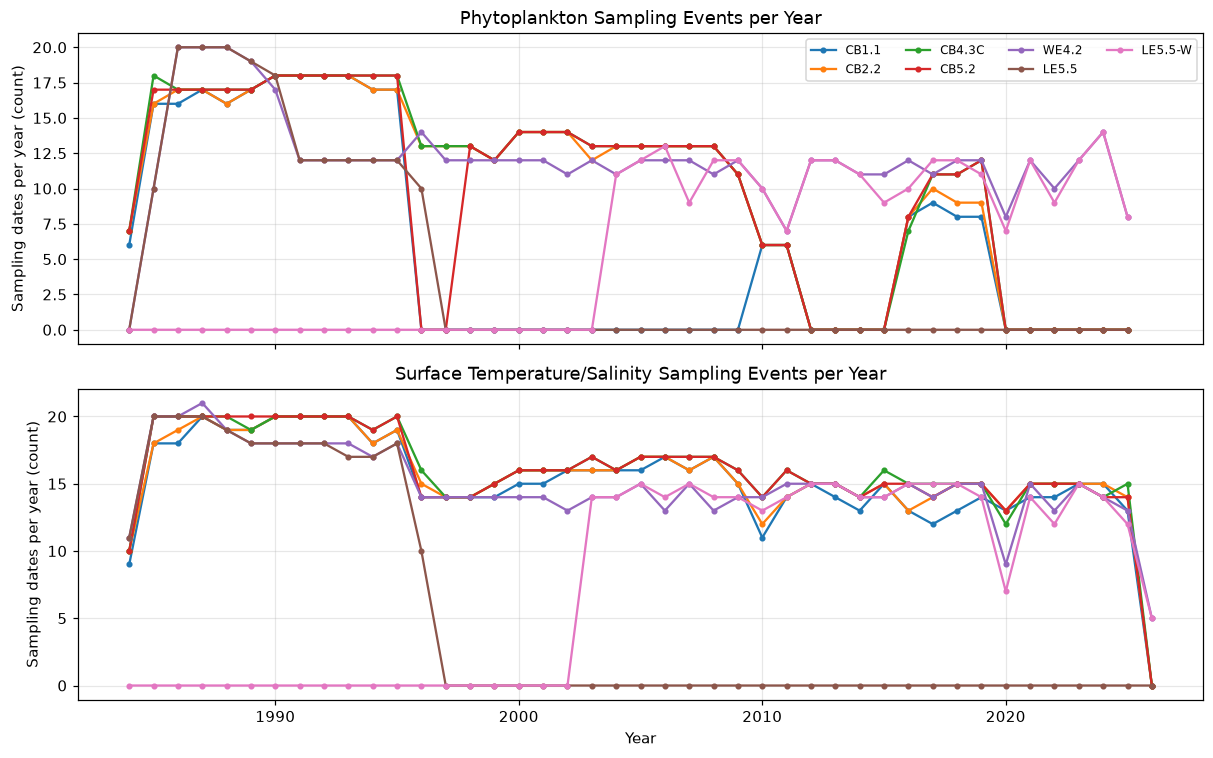

In [12]:
# FIGURE 2: Sampling dates per year
# Plot the number of sampling dates per year at each station for both datasets. Sampling was more frequent in the 1980s-early 1990s, Upper/Middle Bay phytoplankton stops after 2019, and LE5.5 stops in 1996.
def per_year(d):
    d = d.copy()
    d['Year'] = pd.to_datetime(d['SampleDate']).dt.year
    return d.groupby(['Station', 'Year']).size().unstack('Station', fill_value=0)

p_year = per_year(phyto_events)
t_year = per_year(ts_wide)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, tab, title in [(axes[0], p_year, 'Phytoplankton Sampling Events per Year'),
                       (axes[1], t_year, 'Surface Temperature/Salinity Sampling Events per Year')]:
    for st in STATIONS:
        if st in tab:
            ax.plot(tab.index, tab[st], marker='o', ms=3, label=st)
    ax.set_title(title)
    ax.set_ylabel('Sampling dates per year (count)')
    ax.grid(alpha=0.3)
axes[1].set_xlabel('Year')
axes[0].legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

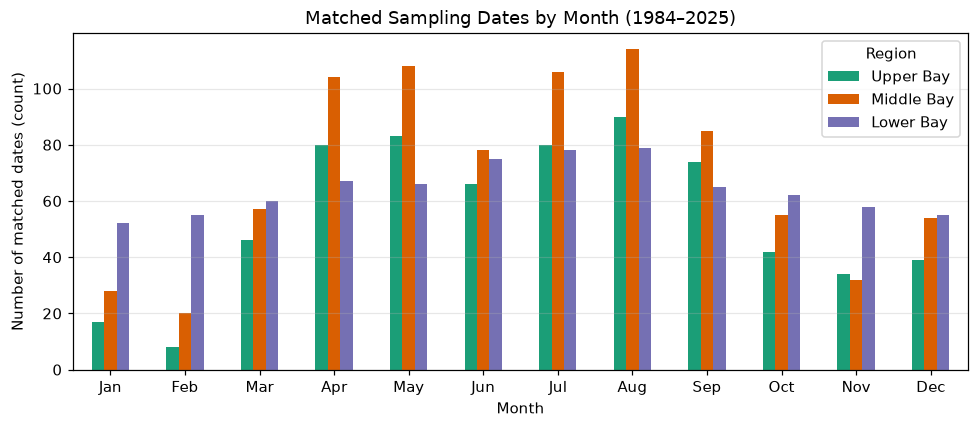

In [13]:
# FIGURE 3: Matched sampling dates by month
# Count matched sampling dates by month and region. Samples are most common April-September and fewest in January-February,
# so winter has the fewest observations (~80-100 per month across all stations).
month_counts = df.groupby(['Month', 'Region']).size().unstack('Region').reindex(columns=REGION_COLORS.keys())
ax = month_counts.plot(kind='bar', figsize=(9, 4), color=[REGION_COLORS[c] for c in month_counts.columns])
ax.set_title('Matched Sampling Dates by Month (1984–2025)')
ax.set_xlabel('Month')
ax.set_ylabel('Number of matched dates (count)')
ax.set_xticklabels(MONTH_NAMES, rotation=0)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## Data Integration and Overlap

### Spatial and temporal overlap

Spatially, the two datasets overlap completely for the six study locations, because both programs sample the same stations on the same cruises. Temporal overlap is high but not complete. Most phytoplankton samples have a temperature/salinity profile from the same day, but some dates exist in only one dataset. The largest gap is the Upper and Middle Bay stations after 2019, which have temperature and salinity data but no phytoplankton counts. The remaining phytoplankton-only dates, most common at WE4.2 in the late 1980s and early 1990s, are mostly samples collected on a different day than the water quality cruise. Dates that appear in only one dataset were dropped in the compiled table.

Status   Both  Phytoplankton only  Temp/Sal only
Station                                         
CB1.1     238                   1            415
CB2.2     421                   4            250
CB4.3C    434                   2            254
CB5.2     407                   3            278
WE4.2     367                 140            274
LE5.5     169                   8             55
LE5.5-W   236                   1             87

Share of phytoplankton dates with same-day T/S: 93.5%


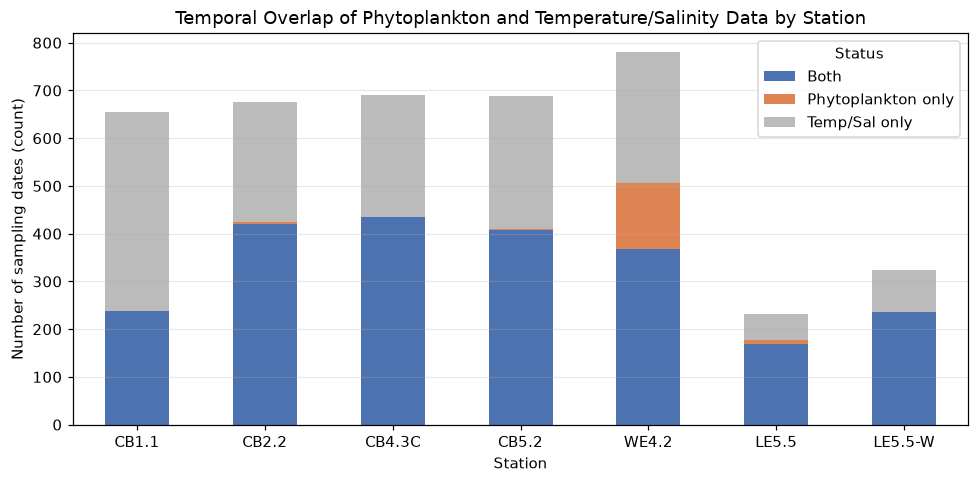

In [14]:
# FIGURE 4: Temporal overlap by station
# Compare, for each station, dates with both datasets vs. phytoplankton only vs. T/S only.
# Most phytoplankton dates have same-day T/S data
p_keys = phyto_events[['Station', 'SampleDate']].assign(phyto=True)
t_keys = ts_wide[['Station', 'SampleDate']].assign(ts=True)
overlap = p_keys.merge(t_keys, on=['Station', 'SampleDate'], how='outer')
overlap['Status'] = np.select(
    [overlap['phyto'].notna() & overlap['ts'].notna(), overlap['phyto'].notna()],
    ['Both', 'Phytoplankton only'], 'Temp/Sal only')

ov = overlap.groupby(['Station', 'Status']).size().unstack(fill_value=0).reindex(STATIONS)
ov = ov[['Both', 'Phytoplankton only', 'Temp/Sal only']]
print(ov)
print(f"\nShare of phytoplankton dates with same-day T/S: {ov['Both'].sum() / (ov['Both'].sum() + ov['Phytoplankton only'].sum()):.1%}")

ax = ov.plot(kind='bar', stacked=True, figsize=(9, 4.5), color=['#4c72b0', '#dd8452', '#bbbbbb'])
ax.set_title('Temporal Overlap of Phytoplankton and Temperature/Salinity Data by Station')
ax.set_xlabel('Station')
ax.set_ylabel('Number of sampling dates (count)')
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Compatibility and resolution alignment

- Spatial: Same stations and coordinates in both datasets, so no spatial interpolation is needed.
- Temporal: Both are discrete samples from the same cruises. I matched records on exact station and date. A small number of phytoplankton samples have a T/S profile one or two days away; these were excluded rather than matched to a nearby date.
- Vertical: This is the main resolution mismatch. Temperature and salinity are point measurements at 0.5–1 m, while phytoplankton samples are composites over the water column above the pycnocline (or the whole water column at the shallow Upper Bay stations). The surface T/S value is used as the best available descriptor of the conditions those cells experienced.
- Units: Temperature (°C) and salinity (ppt) are consistent across the record. Phytoplankton abundance is in cells/L throughout, after treating the 2013–2021 records labeled `L` as cells/L.
- Methods: Counting methods and labs changed over time and differ between the Maryland and Virginia programs, which may affect comparability of absolute cell counts between regions and decades. This will be considered in later analysis.

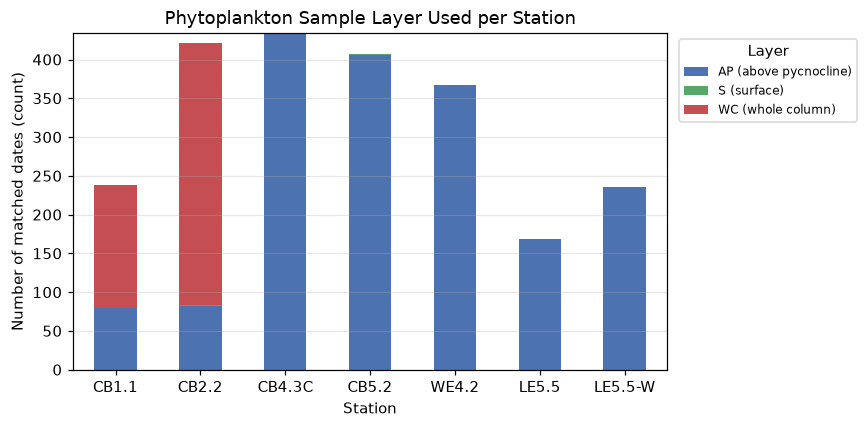

In [15]:
# FIGURE 5: Phytoplankton sample layer used at each station
# Show which phytoplankton sample type was used at each station: CB1.1 and CB2.2 rely mostly on whole-water-column samples,
# while all other stations use above-pycnocline samples.
fig, ax = plt.subplots(figsize=(8, 4))
layer_counts = df.groupby(['Station', 'Phyto_Layer']).size().unstack(fill_value=0).reindex(STATIONS)
layer_counts.plot(kind='bar', stacked=True, ax=ax, color=['#4c72b0', '#55a868', '#c44e52'][:layer_counts.shape[1]])
ax.set_title('Phytoplankton Sample Layer Used per Station')
ax.set_xlabel('Station')
ax.set_ylabel('Number of matched dates (count)')
ax.legend(['AP (above pycnocline)', 'S (surface)', 'WC (whole column)'], title='Layer', fontsize=8,
          bbox_to_anchor=(1.01, 1), loc='upper left')
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## Environmental Conditions: Temperature and Salinity

Before looking at the two species, these figures show what surface temperature and salinity look like at each region over the full record (Figure 6) and through a typical year (Figure 7). These use every surface temperature/salinity measurement (not only the dates matched with phytoplankton), to give the most complete picture of conditions.

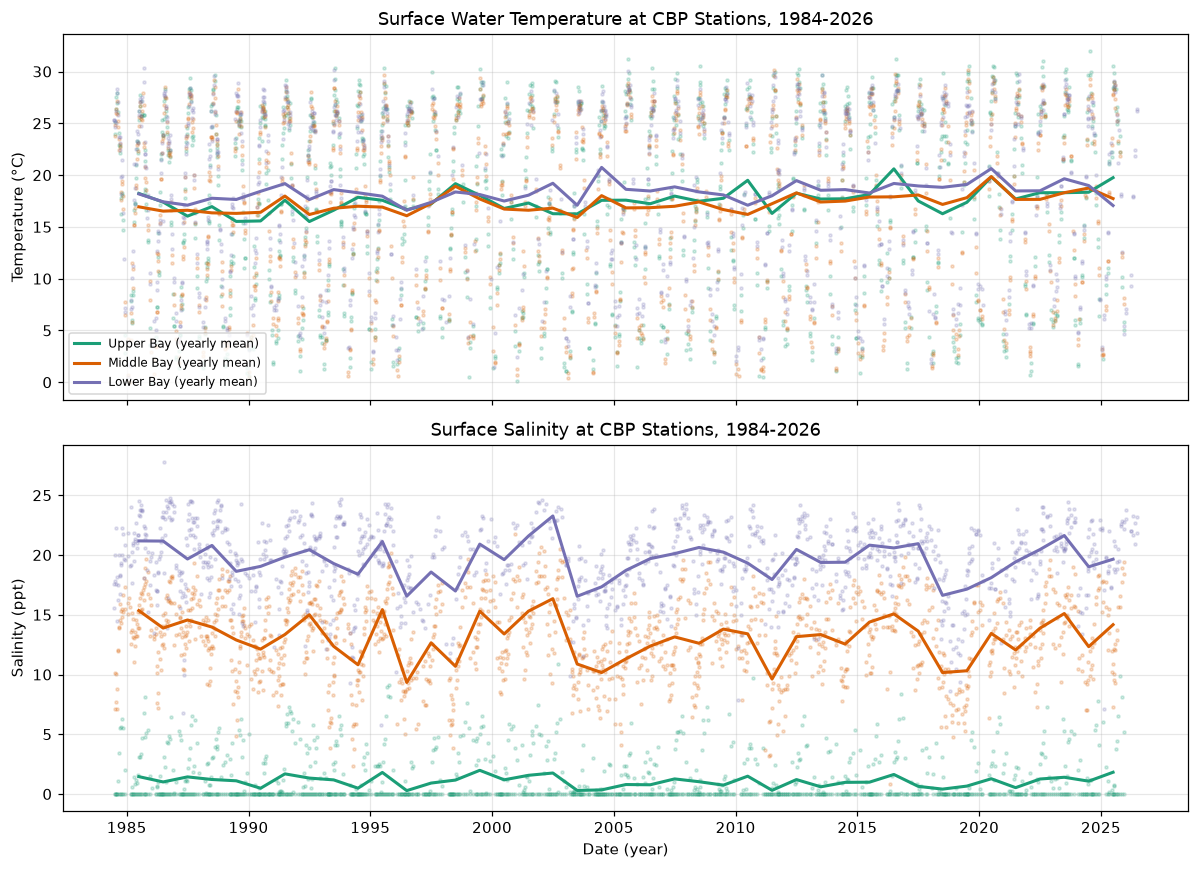

In [16]:
# FIGURE 6: Temperature and salinity time series, by region
# Each dot is one surface measurement (all sampling dates, 1984-2026), colored by region.
# The lines are the yearly average for each region, which makes long-term changes easier to see
# than the individual points. 1984 and 2026 are left out of the yearly averages because they only
# have part of a year of data (1984 starts in June, 2026 ends in June), so their averages would be
# biased toward one part of the year.

# add the region of each station to the surface temperature/salinity table
ts_wide['Region'] = ts_wide['Station'].map(REGION)
ts_wide['Year'] = ts_wide['SampleDate'].dt.year
ts_wide['Month'] = ts_wide['SampleDate'].dt.month

# yearly average temperature and salinity in each region (complete years only, 1985-2025)
annual_mean = (ts_wide[(ts_wide['Year'] > 1984) & (ts_wide['Year'] < 2026)]
               .groupby(['Region', 'Year'])[['Temperature_C', 'Salinity_ppt']]
               .mean()
               .reset_index())

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
variables = [('Temperature_C', 'Temperature (°C)', 'Surface Water Temperature'),
             ('Salinity_ppt', 'Salinity (ppt)', 'Surface Salinity')]

for ax, (var, var_label, title) in zip(axes, variables):
    for region, color in REGION_COLORS.items():
        # all individual measurements (faint dots)
        points = ts_wide[ts_wide['Region'] == region]
        ax.scatter(points['SampleDate'], points[var], s=4, alpha=0.2, color=color)
        # yearly averages (solid line). Dates are placed at the middle of each year (July 1).
        yearly = annual_mean[annual_mean['Region'] == region]
        year_dates = pd.to_datetime(yearly['Year'].astype(str) + '-07-01')
        ax.plot(year_dates, yearly[var], color=color, linewidth=2, label=f'{region} (yearly mean)')
    ax.set_title(f'{title} at CBP Stations, 1984-2026')
    ax.set_ylabel(var_label)
    ax.grid(alpha=0.3)

axes[1].set_xlabel('Date (year)')
axes[0].legend(fontsize=8, loc='lower left')
plt.tight_layout()
plt.show()

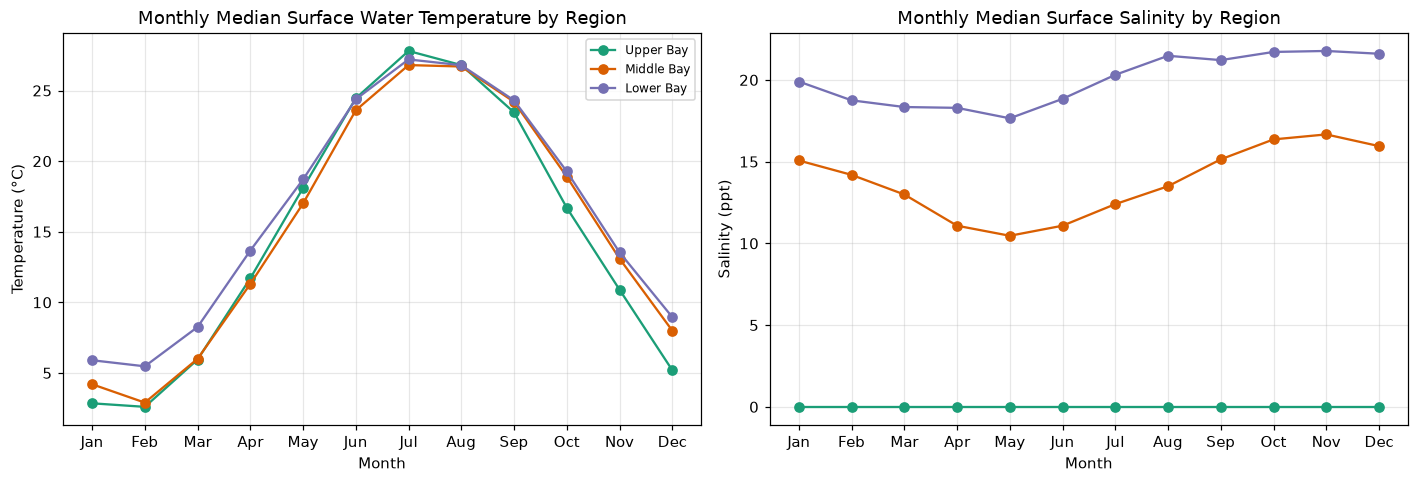

Temperature_C                      Salinity_ppt                     
Region     Lower Bay Middle Bay Upper Bay    Lower Bay Middle Bay Upper Bay
Month                                                                      
1                5.9        4.2       2.8         19.9       15.1       0.0
2                5.5        2.9       2.6         18.8       14.2       0.0
3                8.3        6.0       6.0         18.3       13.0       0.0
4               13.7       11.3      11.7         18.3       11.1       0.0
5               18.7       17.0      18.1         17.6       10.5       0.0
6               24.4       23.6      24.4         18.8       11.1       0.0
7               27.2       26.8      27.8         20.3       12.4       0.0
8               26.8       26.7      26.8         21.5       13.5       0.0
9               24.3       24.2      23.4         21.2       15.1       0.0
10              19.3       18.9      16.7         21.7       16.4       0.0
11              13.5       13.1      10.9         21.8       16.7       0.0
12               9.0        8.0       5.2         21.6       16.0       0.0

In [17]:
# FIGURE 7: Seasonal cycle of temperature and salinity, by region
# The median surface temperature and salinity in each month, for each region, across all years.
# This shows what conditions are like through a typical year, which helps explain WHEN each
# species occurs (Part 1) and links season to the temperature/salinity conditions in Part 2.

monthly_median = (ts_wide.groupby(['Region', 'Month'])[['Temperature_C', 'Salinity_ppt']]
                  .median()
                  .reset_index())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (var, var_label, title) in zip(axes, variables):
    for region, color in REGION_COLORS.items():
        g = monthly_median[monthly_median['Region'] == region]
        ax.plot(g['Month'], g[var], marker='o', color=color, label=region)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MONTH_NAMES)
    ax.set_title(f'Monthly Median {title} by Region')
    ax.set_xlabel('Month')
    ax.set_ylabel(var_label)
    ax.grid(alpha=0.3)

axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# print the table of monthly medians so the values can be quoted in the report
monthly_median.pivot(index='Month', columns='Region', values=['Temperature_C', 'Salinity_ppt']).round(1)

**Environmental conditions results.** Yearly average surface temperature stays between about 16 and 21 °C in all three regions, with no strong long-term trend visible over 1985–2025 (Figure 6). Salinity shows the expected gradient down the Bay: near 0 ppt in the Upper Bay, about 10–17 ppt in the Middle Bay, and about 17–22 ppt in the Lower Bay. Yearly salinity drops noticeably in some years (for example 1996, 2003–2004, 2011, and 2018–2019), likely reflecting wet years with high river flow. Through a typical year (Figure 7), surface water is coldest in February (median 2.6–5.5 °C, warmest in the Lower Bay) and warmest in July (about 27–28 °C). Salinity in the Middle and Lower Bay is lowest in spring (April–May) and highest in fall, as spring river flow freshens the Bay. These seasonal patterns line up with the species results below: in winter (December–March) the Middle and Lower Bay are cold (about 3–9 °C) and moderately salty (about 13–22 ppt), the conditions where *H. triquetra* is most common, and in April–May the Middle Bay is about 11–17 °C and 10–11 ppt, close to the conditions of *P. minimum*'s highest abundances.

## Part 1: When and where do the species occur and bloom?

A sample is counted as a **bloom** when abundance is above:
- *H. triquetra*: **10⁶ cells/L**. Blooms of this species typically reach ~2–10 × 10⁶ cells/L (Litaker et al., 2002).
- *P. minimum*: **3,000 cells/mL**, the Chesapeake Bay bloom definition used by Tango et al. (2005), based on the level where impacts on living resources are expected. Converted to the units of the data (1,000 mL = 1 L), this is **3 × 10⁶ cells/L**.

In [18]:
# Settings for the analysis (Parts 1-4)

# Bloom thresholds, all in cells/L (the units of the data).
#  - H. triquetra: > 10^6 cells/L. Blooms typically reach ~2-10 x 10^6 cells/L (Litaker et al., 2002).
#  - P. minimum:   > 3,000 cells/mL, the Chesapeake Bay bloom definition used by Tango et al. (2005),
#                  based on where impacts on living resources are expected. There are 1,000 mL in 1 L,
#                  so 3,000 cells/mL x 1,000 = 3 x 10^6 cells/L.
BLOOM_THRESHOLD = {
    'H_triquetra_cells_L': 1e6,          # 1,000,000 cells/L
    'P_minimum_cells_L': 3000 * 1000,    # 3,000 cells/mL converted to cells/L (3,000,000 cells/L)
}

# Labels for the bloom thresholds, used in figure legends and titles
BLOOM_LABEL = {
    'H_triquetra_cells_L': '10$^6$ cells/L',
    'P_minimum_cells_L': '3 × 10$^6$ cells/L',
}

# Full species names to use in figure titles, matched to their column names
SPECIES = {
    'H_triquetra_cells_L': 'Heterocapsa triquetra',
    'P_minimum_cells_L': 'Prorocentrum minimum',
}

# (REGION_COLORS, STATION_ORDER, and MONTH_NAMES are defined in the first code cell)

In [19]:
# Label each sample as present / bloom for each species
# For each species we add two True/False columns:
#   *_present : the species was found in the sample (abundance > 0)
#   *_bloom   : the abundance is above that species' bloom threshold

for col in SPECIES:
    df[col.replace('_cells_L', '_present')] = df[col] > 0
    df[col.replace('_cells_L', '_bloom')] = df[col] > BLOOM_THRESHOLD[col]

# Build a small summary table: how often each species is present and blooming
rows = []
for col, name in SPECIES.items():
    present = df[col] > 0
    bloom = df[col] > BLOOM_THRESHOLD[col]
    rows.append({
        'Species': name,
        'Bloom threshold (cells/L)': f'{BLOOM_THRESHOLD[col]:,.0f}',
        'Samples': len(df),
        'Samples present': present.sum(),
        '% present': round(present.mean() * 100, 1),
        'Bloom samples': bloom.sum(),
        '% bloom': round(bloom.mean() * 100, 1),
        'Max abundance (cells/L)': f'{df[col].max():,.0f}',
    })
bloom_summary = pd.DataFrame(rows)
bloom_summary

,Species,Bloom threshold (cells/L),Samples,Samples present,% present,Bloom samples,% bloom,Max abundance (cells/L)
0,Heterocapsa triquetra,"1,000,000",2272,516,22.7,4,0.2,"2,955,264"
1,Prorocentrum minimum,"3,000,000",2272,1369,60.3,9,0.4,"9,331,867"


In [20]:
# List every bloom event so we can see exactly when and where they happened
for col, name in SPECIES.items():
    blooms = df[df[col] > BLOOM_THRESHOLD[col]]
    print(f'{name}: {len(blooms)} bloom samples')
    print(blooms[['Station', 'Region', 'SampleDate', col, 'Temperature_C', 'Salinity_ppt']]
          .sort_values('SampleDate').to_string(index=False))
    print()

Heterocapsa triquetra: 4 bloom samples
Station    Region SampleDate  H_triquetra_cells_L  Temperature_C  Salinity_ppt
  CB2.2 Upper Bay 1987-03-16            2448594.0           4.60          4.90
  LE5.5 Lower Bay 1993-03-12            1913242.0           7.70         12.10
  CB2.2 Upper Bay 2002-03-15            1070420.0           7.70          4.00
LE5.5-W Lower Bay 2014-02-17            2955264.0           3.29         17.82

Prorocentrum minimum: 9 bloom samples
Station     Region SampleDate  P_minimum_cells_L  Temperature_C  Salinity_ppt
  CB2.2  Upper Bay 1992-05-28          5079255.0         16.800       3.47000
 CB4.3C Middle Bay 1998-05-19          3017653.0         19.600       3.82642
 CB4.3C Middle Bay 2000-04-25          5140240.0         11.900       8.50000
 CB4.3C Middle Bay 2000-05-09          9331867.0         18.700       8.38000
 CB4.3C Middle Bay 2003-05-20          5370400.0         15.800       9.08000
 CB4.3C Middle Bay 2008-05-15          4300746.0         16

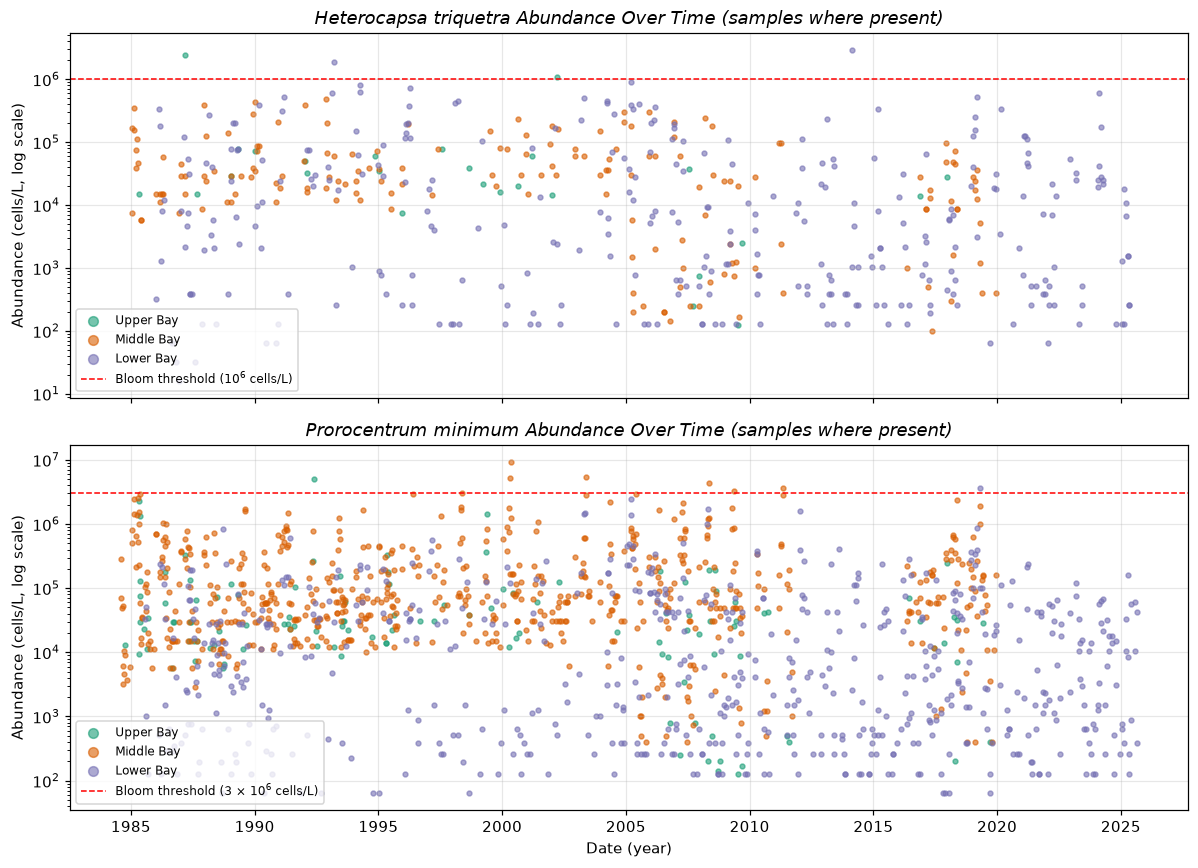

In [21]:
# FIGURE 8: Concentrations over time
# One panel per species. Each dot is one sample where the species was present, colored by region. 
# The y-axis is on a log scale because abundances range from tens to millions of cells/L. The dashed line marks the bloom threshold.

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

for ax, (col, name) in zip(axes, SPECIES.items()):
    # loop through regions so each gets its own color and legend entry
    for region, color in REGION_COLORS.items():
        subset = df[(df['Region'] == region) & (df[col] > 0)]
        ax.scatter(subset['SampleDate'], subset[col], s=10, alpha=0.6,
                   color=color, label=region)
    # bloom threshold line
    ax.axhline(BLOOM_THRESHOLD[col], color='red', linestyle='--', linewidth=1,
               label=f'Bloom threshold ({BLOOM_LABEL[col]})')
    ax.set_yscale('log')
    ax.set_title(f'{name} Abundance Over Time (samples where present)', style='italic')
    ax.set_ylabel('Abundance (cells/L, log scale)')
    ax.grid(alpha=0.3)

axes[1].set_xlabel('Date (year)')
axes[0].legend(fontsize=8, markerscale=2, loc='lower left')
axes[1].legend(fontsize=8, markerscale=2, loc='lower left')
plt.tight_layout()
plt.show()

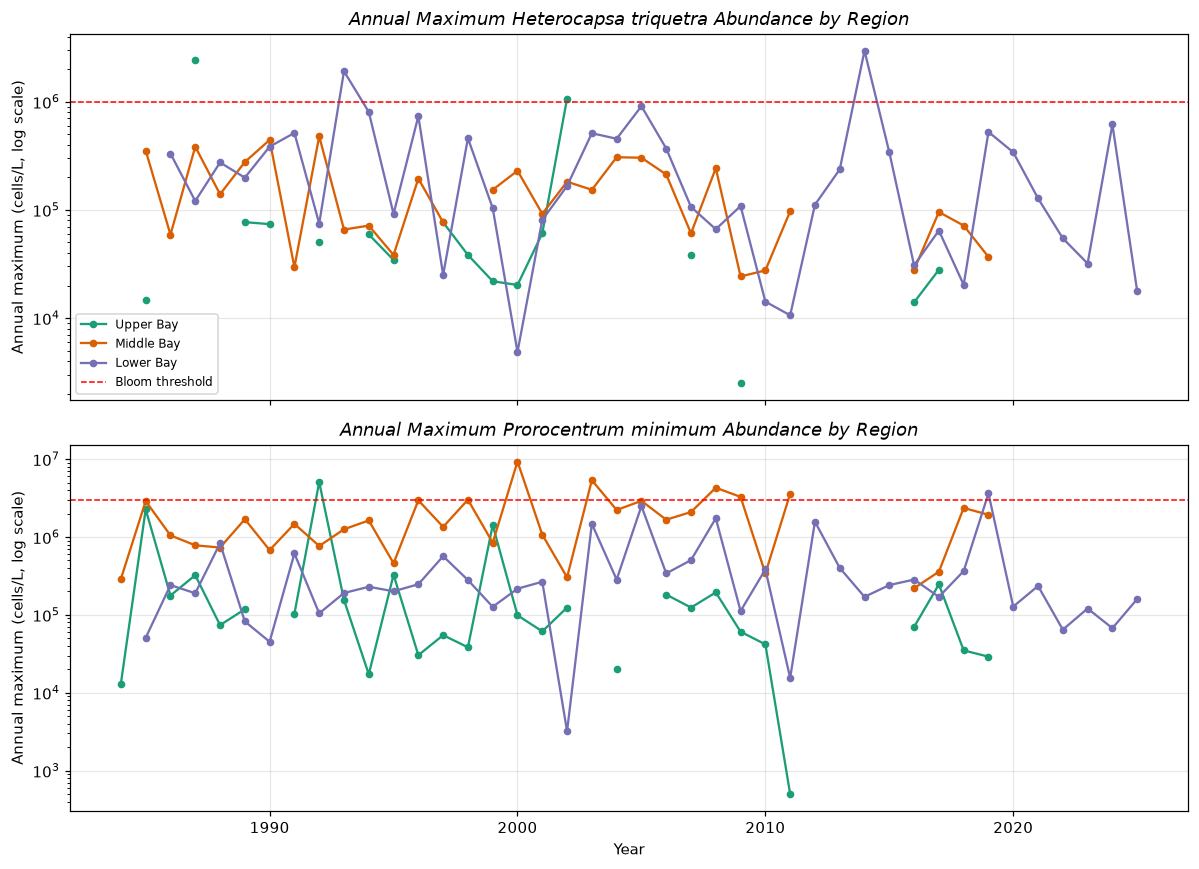

In [22]:
# FIGURE 9: Highest concentration each year, by region
# The number of samples per year changes over time, so instead of counting blooms we look at the HIGHEST abundance recorded each year in each region.
# This shows whether peak concentrations have changed over the 40 years.

# groupby: split the data into groups by Year and Region, then take the maximum abundance in each group
annual_max = df.groupby(['Year', 'Region'])[list(SPECIES)].max().reset_index()

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

for ax, (col, name) in zip(axes, SPECIES.items()):
    for region, color in REGION_COLORS.items():
        subset = annual_max[(annual_max['Region'] == region) & (annual_max[col] > 0)]
        # reindex fills in any missing years with empty values (NaN), so the
        # line breaks at gaps instead of drawing across years with no data
        subset = subset.set_index('Year').reindex(range(1984, 2027))
        ax.plot(subset.index, subset[col], marker='o', markersize=4,
                color=color, label=region)
    ax.axhline(BLOOM_THRESHOLD[col], color='red', linestyle='--', linewidth=1,
               label='Bloom threshold')
    ax.set_yscale('log')
    ax.set_title(f'Annual Maximum {name} Abundance by Region', style='italic')
    ax.set_ylabel('Annual maximum (cells/L, log scale)')
    ax.grid(alpha=0.3)

axes[1].set_xlabel('Year')
axes[0].legend(fontsize=8, loc='lower left')
plt.tight_layout()
plt.show()

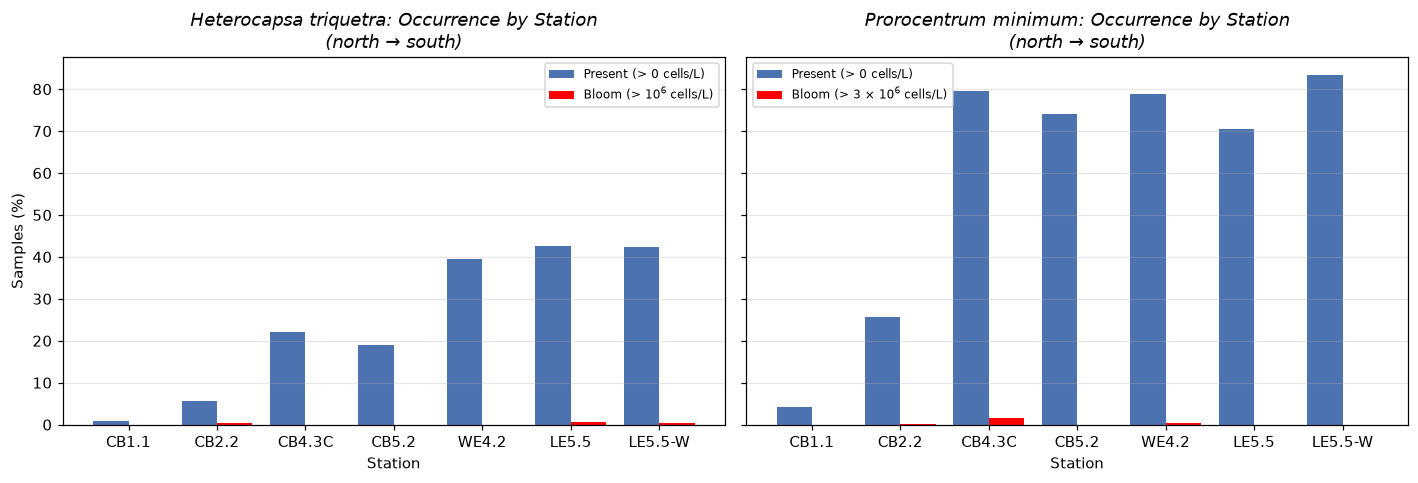

In [23]:
# FIGURE 10: Where in the Bay each species occurs and blooms
# For each station (ordered north to south) we calculate:
#   - % of samples where the species was present
#   - % of samples that were blooms
# Using percentages instead of counts makes stations with different numbers of samples comparable.

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
x = np.arange(len(STATION_ORDER))   # bar positions: 0, 1, 2, ...
width = 0.4                          # width of each bar

for ax, (col, name) in zip(axes, SPECIES.items()):
    pct_present = []
    pct_bloom = []
    for station in STATION_ORDER:
        station_data = df[df['Station'] == station]
        pct_present.append((station_data[col] > 0).mean() * 100)
        pct_bloom.append((station_data[col] > BLOOM_THRESHOLD[col]).mean() * 100)

    # two bars per station, side by side
    ax.bar(x - width / 2, pct_present, width, color='#4c72b0', label='Present (> 0 cells/L)')
    ax.bar(x + width / 2, pct_bloom, width, color='red', label=f'Bloom (> {BLOOM_LABEL[col]})')
    ax.set_xticks(x)
    ax.set_xticklabels(STATION_ORDER)
    ax.set_title(f'{name}: Occurrence by Station\n(north → south)', style='italic')
    ax.set_xlabel('Station')
    ax.grid(axis='y', alpha=0.3)

axes[0].set_ylabel('Samples (%)')
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

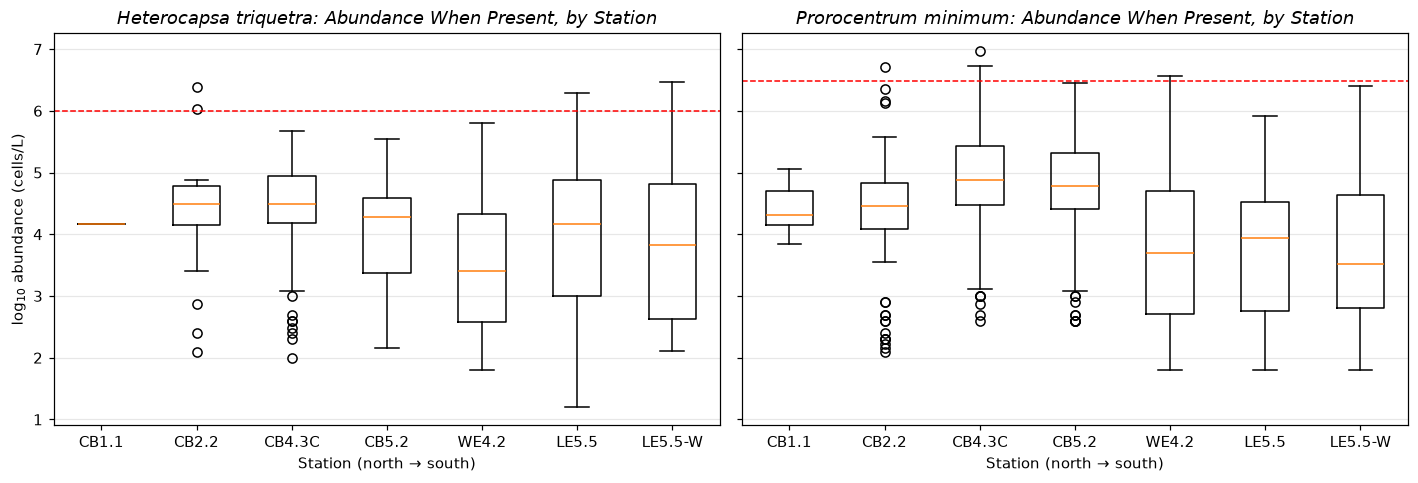

In [24]:
# FIGURE 11: Typical concentration by station (when present)
# Box plots of abundance at each station, using only samples where the species was present. log10 is used so 10^3, 10^4, 10^5 cells/L appear as
# 3, 4, 5. The box shows the middle 50% of values, the line inside is the median, and the dashed red line is the bloom threshold
# (6 for H. triquetra = log10(10^6), and about 6.5 for P. minimum = log10(3 x 10^6)).

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for ax, (col, name) in zip(axes, SPECIES.items()):
    # make a list with one set of values per station
    data = []
    for station in STATION_ORDER:
        values = df.loc[(df['Station'] == station) & (df[col] > 0), col]
        data.append(np.log10(values))
    ax.boxplot(data)
    ax.set_xticks(range(1, len(STATION_ORDER) + 1))
    ax.set_xticklabels(STATION_ORDER)
    ax.axhline(np.log10(BLOOM_THRESHOLD[col]), color='red', linestyle='--', linewidth=1)
    ax.set_title(f'{name}: Abundance When Present, by Station', style='italic')
    ax.set_xlabel('Station (north → south)')
    ax.grid(axis='y', alpha=0.3)

axes[0].set_ylabel('log$_{10}$ abundance (cells/L)')
plt.tight_layout()
plt.show()

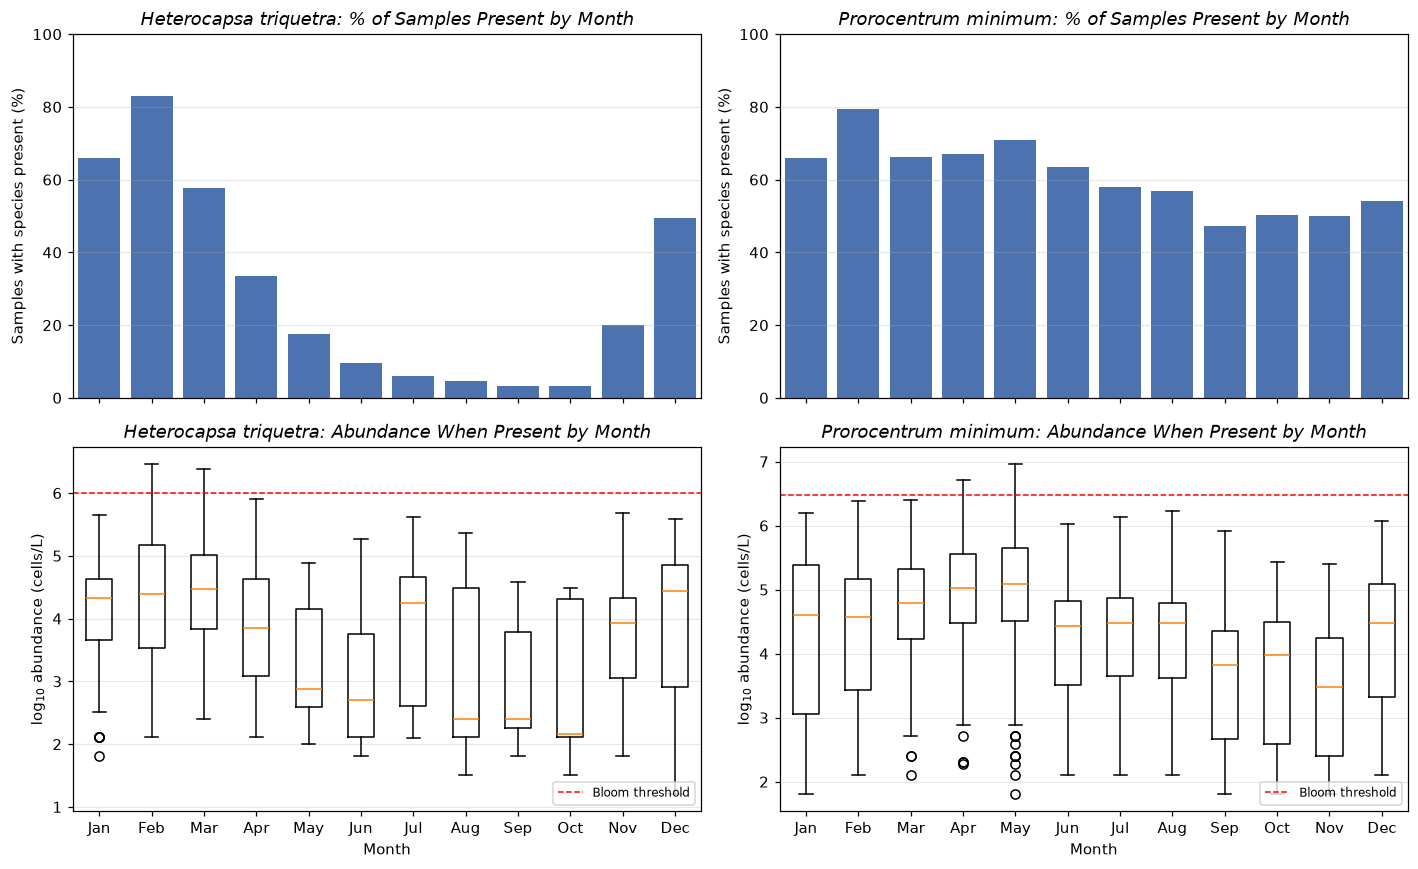

In [25]:
# FIGURE 12: When during the year each species occurs (seasonal cycle)
# Top row: % of samples in each month where the species was present.
# Bottom row: abundance in each month when present (box plots, log10), with the bloom threshold as a dashed red line.

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)

for i, (col, name) in enumerate(SPECIES.items()):
    # --- top: % present by month ---
    pct_present = []
    for month in range(1, 13):
        month_data = df[df['Month'] == month]
        pct_present.append((month_data[col] > 0).mean() * 100)
    axes[0, i].bar(range(1, 13), pct_present, color='#4c72b0')
    axes[0, i].set_title(f'{name}: % of Samples Present by Month', style='italic')
    axes[0, i].set_ylabel('Samples with species present (%)')
    axes[0, i].set_ylim(0, 100)
    axes[0, i].grid(axis='y', alpha=0.3)

    # --- bottom: abundance by month when present ---
    data = []
    for month in range(1, 13):
        values = df.loc[(df['Month'] == month) & (df[col] > 0), col]
        data.append(np.log10(values))
    axes[1, i].boxplot(data, positions=range(1, 13))
    axes[1, i].axhline(np.log10(BLOOM_THRESHOLD[col]), color='red', linestyle='--',
                       linewidth=1, label='Bloom threshold')
    axes[1, i].set_title(f'{name}: Abundance When Present by Month', style='italic')
    axes[1, i].set_ylabel('log$_{10}$ abundance (cells/L)')
    axes[1, i].set_xlabel('Month')
    axes[1, i].grid(axis='y', alpha=0.3)
    axes[1, i].legend(fontsize=8, loc='lower right')

for ax in axes[1]:
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MONTH_NAMES)

plt.tight_layout()
plt.show()

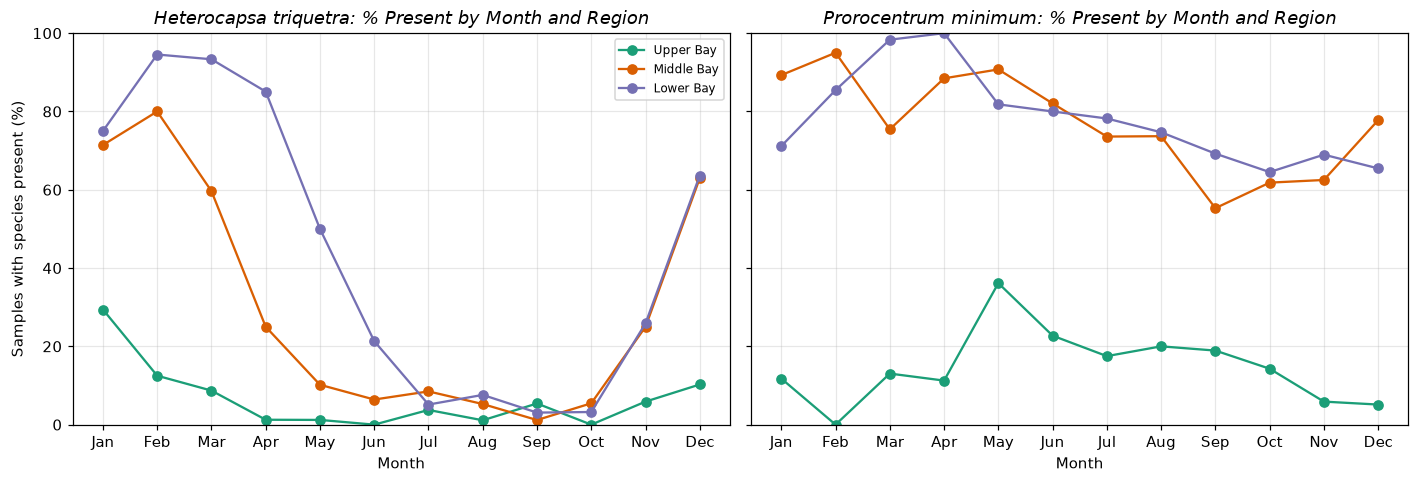

In [26]:
# FIGURE 13: Seasonal cycle in each region
# Same idea as the top row of Figure 5, but split by region, to see whether the timing of each species differs between the Upper, Middle, and Lower Bay.

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for ax, (col, name) in zip(axes, SPECIES.items()):
    for region, color in REGION_COLORS.items():
        region_data = df[df['Region'] == region]
        pct_present = []
        for month in range(1, 13):
            month_data = region_data[region_data['Month'] == month]
            pct_present.append((month_data[col] > 0).mean() * 100)
        ax.plot(range(1, 13), pct_present, marker='o', color=color, label=region)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MONTH_NAMES)
    ax.set_title(f'{name}: % Present by Month and Region', style='italic')
    ax.set_xlabel('Month')
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.3)

axes[0].set_ylabel('Samples with species present (%)')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

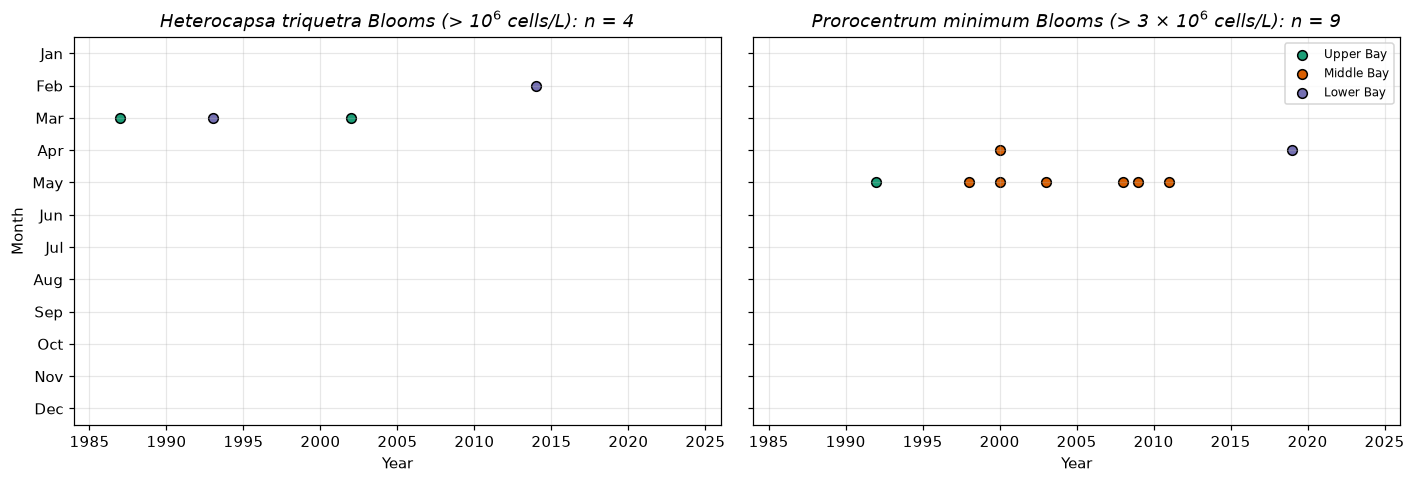

In [27]:
# FIGURE 14: Bloom calendar - when each bloom happened
# Each dot is one bloom sample, placed by year (x) and month (y) and colored by region
# Shows which months blooms happen in and whether bloom timing has changed over the years.

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for ax, (col, name) in zip(axes, SPECIES.items()):
    blooms = df[df[col] > BLOOM_THRESHOLD[col]]
    for region, color in REGION_COLORS.items():
        subset = blooms[blooms['Region'] == region]
        ax.scatter(subset['Year'], subset['Month'], s=40, color=color,
                   edgecolor='k', label=region)
    ax.set_title(f'{name} Blooms (> {BLOOM_LABEL[col]}): n = {len(blooms)}', style='italic')
    ax.set_xlabel('Year')
    ax.set_xlim(1984, 2026)
    ax.grid(alpha=0.3)

axes[0].set_yticks(range(1, 13))
axes[0].set_yticklabels(MONTH_NAMES)
axes[0].set_ylim(12.5, 0.5)      # January at the top, December at the bottom
axes[0].set_ylabel('Month')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Part 1 results.** *H. triquetra* was present in 23% of samples but reached bloom levels only 4 times (CB2.2 in 1987 and 2002, LE5.5 in 1993, and LE5.5-W in 2014), all in February or March. It is a winter–spring species: it is most common from December to April (present in 83% of February samples), nearly absent from June to October, and rare at the fresh Upper Bay stations. *P. minimum* was present in 60% of samples and reached the Tango et al. (2005) bloom level only 9 times (0.4% of samples), all in April or May: 7 at CB4.3C in the Middle Bay (1998, 2000 twice, 2003, 2008, 2009, and 2011), plus CB2.2 in 1992 and WE4.2 in 2019. It occurs year-round but is most common and abundant in spring.

## Part 2: Temperature and salinity conditions

Each sample is grouped as **absent**, **low**, or **high** for each species, and temperature and salinity are compared between the groups. Because both species reached their bloom thresholds too rarely to describe conditions (4 samples for *H. triquetra* and 9 for *P. minimum*), "high" in Parts 2–4 means an **elevated** level: **> 10⁵ cells/L** for *H. triquetra* (85 samples) and **> 10⁶ cells/L** for *P. minimum* (50 samples with temperature and salinity data).

In [28]:
# TEMPERATURE AND SALINITY CONDITIONS
# Describe the temperature and salinity conditions where each species is absent, present at low levels, or present at high levels.

# "High" threshold for this part (cells/L):
#  - H. triquetra: elevated level, > 10^5 cells/L.
#    Only 4 samples are above the 10^6 bloom threshold, which is too few to describe conditions, so I used 10^5 here instead.
#  - P. minimum:   elevated level, > 10^6 cells/L (about 50 samples).
#    Only 9 samples are above the 3 x 10^6 bloom threshold, which is too few to describe conditions, so I used 10^6 here instead.

HIGH_THRESHOLD = {
    'H_triquetra_cells_L': 1e5,
    'P_minimum_cells_L': 1e6,
}
HIGH_LABEL = {
    'H_triquetra_cells_L': 'Elevated (> 10$^5$ cells/L)',
    'P_minimum_cells_L': 'Elevated (> 10$^6$ cells/L)',
}

# Some samples are missing temperature or salinity, so drop them for this part
ts_df = df.dropna(subset=['Temperature_C', 'Salinity_ppt']).copy()
print('Samples with both temperature and salinity:', len(ts_df))

# Put each sample into one of three groups for each species:
#   'Absent'  : 0 cells/L
#   'Low'     : present, but at or below the high threshold
#   'High'    : above the high threshold
CATEGORIES = ['Absent', 'Low', 'High']

def abundance_group(value, threshold):
    """Return 'Absent', 'Low', or 'High' for one abundance value."""
    if value == 0:
        return 'Absent'
    elif value <= threshold:
        return 'Low'
    else:
        return 'High'

for col in SPECIES:
    group_col = col.replace('_cells_L', '_group')
    # .apply runs the abundance_group function on every value in the column
    ts_df[group_col] = ts_df[col].apply(abundance_group, args=(HIGH_THRESHOLD[col],))
    print(SPECIES[col], ts_df[group_col].value_counts().reindex(CATEGORIES).to_dict())

Samples with both temperature and salinity: 2262
Heterocapsa triquetra {'Absent': 1749, 'Low': 428, 'High': 85}
Prorocentrum minimum {'Absent': 899, 'Low': 1313, 'High': 50}


In [29]:
# Temperature and salinity ranges for each group
# For each species and group we report the median and the 10th-90th percentile range. 
# The 10th-90th percentile range is where the middle 80% of samples fall, so it is a good summary of the "typical" conditions without
# being thrown off by a few unusual samples.

rows = []
for col, name in SPECIES.items():
    group_col = col.replace('_cells_L', '_group')
    for group in CATEGORIES:
        g = ts_df[ts_df[group_col] == group]
        rows.append({
            'Species': name,
            'Group': group,
            'n samples': len(g),
            'Temp median (°C)': round(g['Temperature_C'].median(), 1),
            'Temp 10-90% (°C)': f"{g['Temperature_C'].quantile(0.1):.1f} - {g['Temperature_C'].quantile(0.9):.1f}",
            'Sal median (ppt)': round(g['Salinity_ppt'].median(), 1),
            'Sal 10-90% (ppt)': f"{g['Salinity_ppt'].quantile(0.1):.1f} - {g['Salinity_ppt'].quantile(0.9):.1f}",
        })
ts_summary = pd.DataFrame(rows)
ts_summary

,Species,Group,n samples,Temp median (°C),Temp 10-90% (°C),Sal median (ppt),Sal 10-90% (ppt)
0,Heterocapsa triquetra,Absent,1749,22.1,8.4 - 27.4,11.9,0.0 - 21.4
1,Heterocapsa triquetra,Low,428,9.9,4.1 - 22.5,16.8,8.3 - 22.0
2,Heterocapsa triquetra,High,85,7.4,3.3 - 12.5,15.7,10.9 - 19.0
3,Prorocentrum minimum,Absent,899,20.5,5.3 - 27.1,2.7,0.0 - 20.7
4,Prorocentrum minimum,Low,1313,18.9,5.9 - 27.2,15.3,6.4 - 21.9
5,Prorocentrum minimum,High,50,16.4,7.7 - 19.6,9.7,4.6 - 15.7


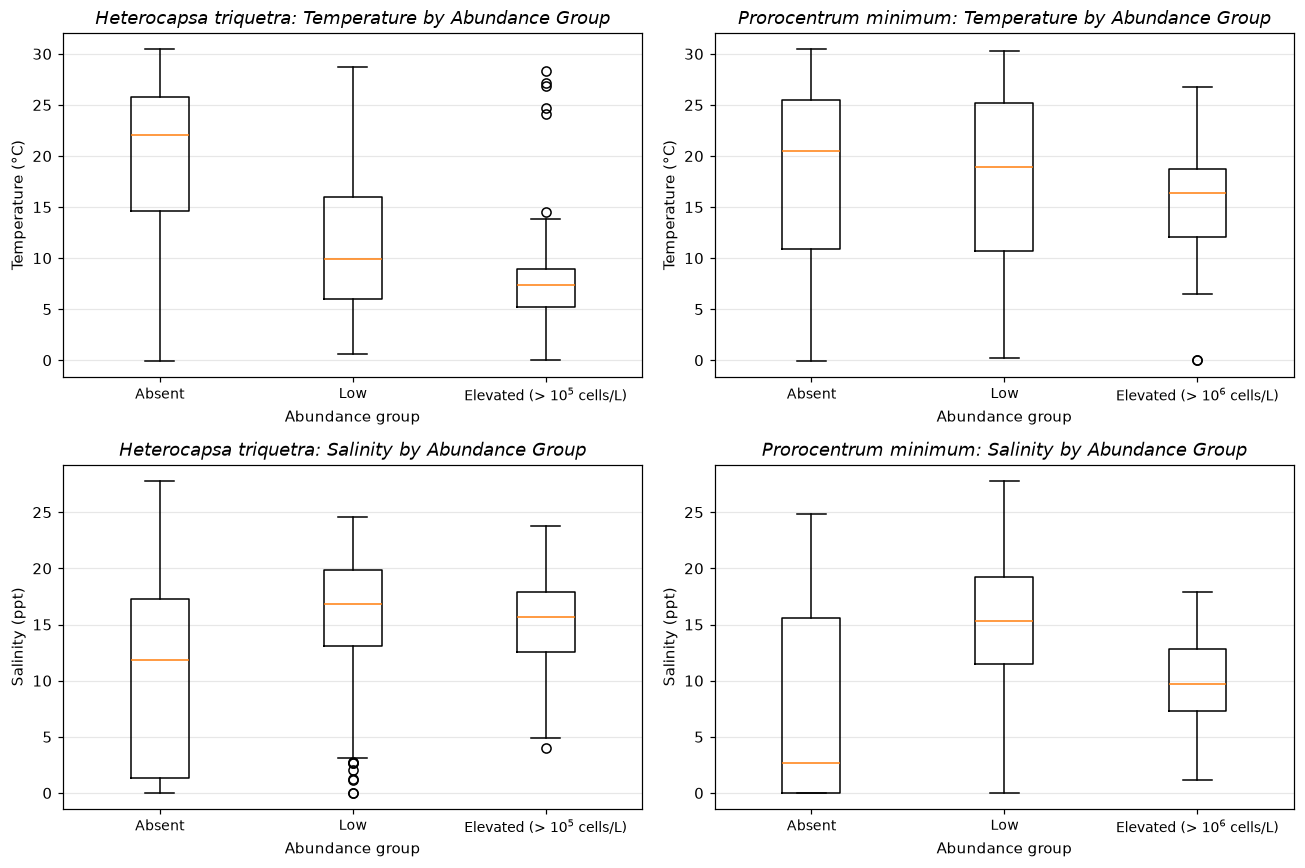

In [30]:
# FIGURE 15: Temperature and salinity by abundance group
# Box plots comparing temperature (top row) and salinity (bottom row) when each species is absent, present at low levels, or present at high levels.
# If the "High" box sits in a different place than the "Absent" box, that variable is related to where/when the species reaches high abundance.

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
variables = [('Temperature_C', 'Temperature (°C)'), ('Salinity_ppt', 'Salinity (ppt)')]

for j, (col, name) in enumerate(SPECIES.items()):
    group_col = col.replace('_cells_L', '_group')
    tick_labels = ['Absent', 'Low', HIGH_LABEL[col]]
    for i, (var, var_label) in enumerate(variables):
        ax = axes[i, j]
        # one set of values per group, in the order Absent, Low, High
        data = [ts_df.loc[ts_df[group_col] == group, var] for group in CATEGORIES]
        ax.boxplot(data)
        ax.set_xticks([1, 2, 3])
        ax.set_xticklabels(tick_labels, fontsize=9)
        ax.set_title(f'{name}: {var_label.split(" (")[0]} by Abundance Group', style='italic')
        ax.set_ylabel(var_label)
        ax.set_xlabel('Abundance group')
        ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

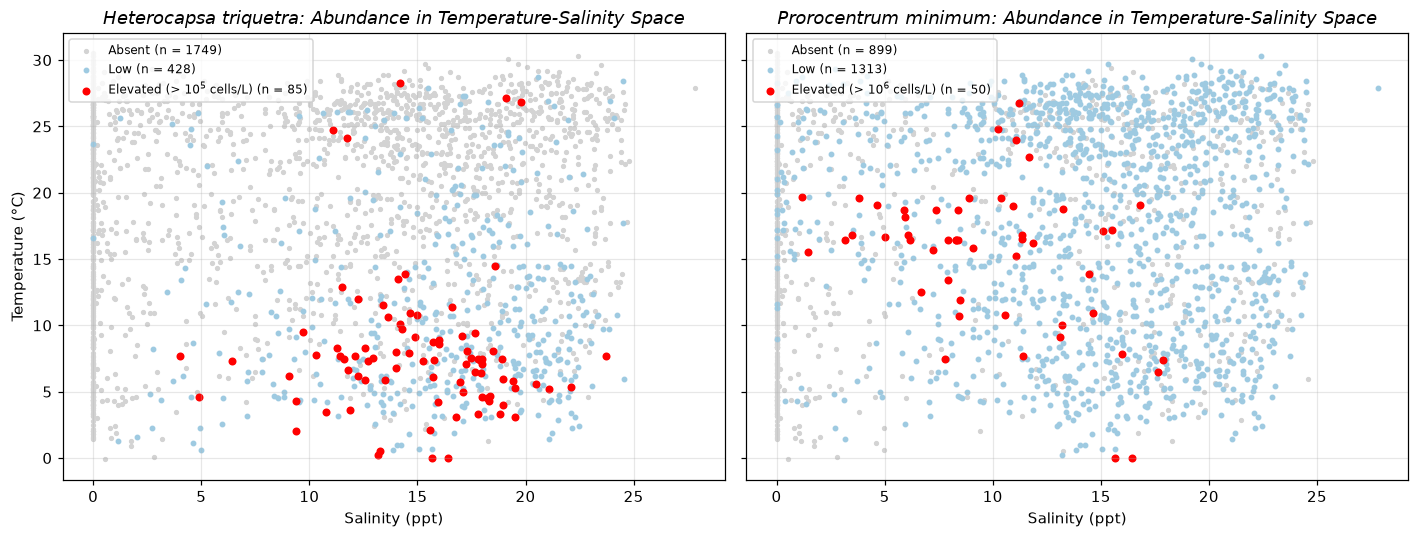

In [31]:
# FIGURE 16: Where high abundances fall in temperature-salinity space
# Each dot is one sample, plotted by salinity (x) and temperature (y).
# Grey = absent, light blue = low, red = high. This shows the combination of temperature AND salinity where each species reaches high abundance.

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
group_style = {
    'Absent': ('lightgrey', 6, 'Absent'),
    'Low': ('#9ecae1', 8, 'Low'),
    'High': ('red', 18, None),     # label filled in below for each species
}

for ax, (col, name) in zip(axes, SPECIES.items()):
    group_col = col.replace('_cells_L', '_group')
    # plot Absent first, then Low, then High, so the high points end up on top
    for group in CATEGORIES:
        color, size, label = group_style[group]
        if group == 'High':
            label = HIGH_LABEL[col]
        g = ts_df[ts_df[group_col] == group]
        ax.scatter(g['Salinity_ppt'], g['Temperature_C'], s=size, color=color,
                   label=f'{label} (n = {len(g)})')
    ax.set_title(f'{name}: Abundance in Temperature-Salinity Space', style='italic')
    ax.set_xlabel('Salinity (ppt)')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='upper left')

axes[0].set_ylabel('Temperature (°C)')
plt.tight_layout()
plt.show()

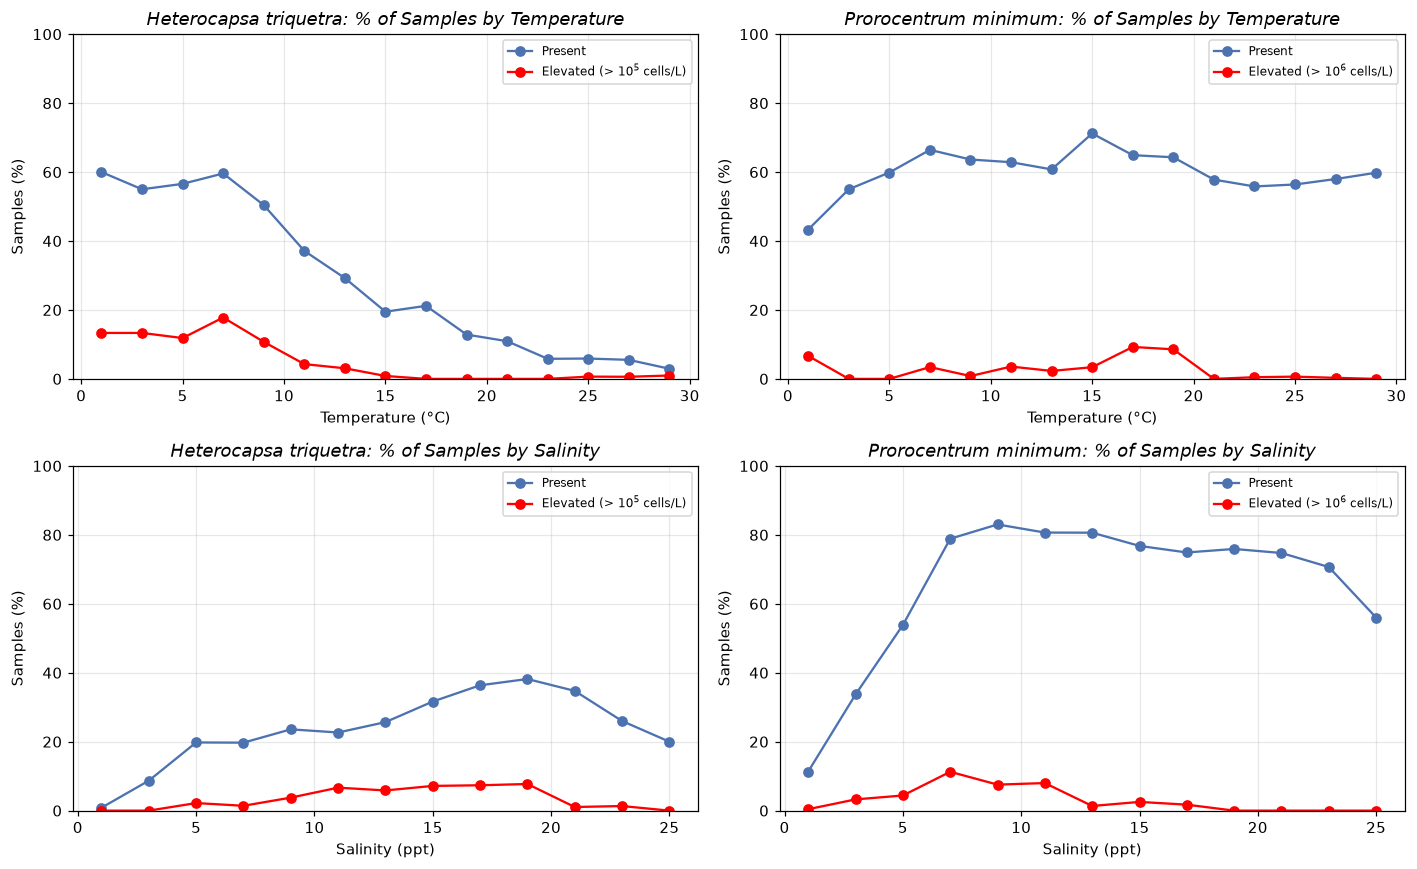

In [32]:
# FIGURE 17: How often each species is present / high across temperature and salinity ranges
# Split temperature into 2 °C bins (0-2, 2-4, ...) and salinity into 2 ppt bins, then calculate the % of samples in each bin where the species
# was present and where it was high. Peaks show the temperatures and salinities where each species is most likely to occur or reach high levels.

temp_bins = np.arange(0, 34, 2)   # 0, 2, 4, ..., 32 °C
sal_bins = np.arange(0, 30, 2)    # 0, 2, 4, ..., 28 ppt

# pd.cut assigns each sample to a bin
ts_df['temp_bin'] = pd.cut(ts_df['Temperature_C'], temp_bins, right=False)
ts_df['sal_bin'] = pd.cut(ts_df['Salinity_ppt'], sal_bins, right=False)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for j, (col, name) in enumerate(SPECIES.items()):
    for i, (bin_col, bins, var_label) in enumerate([('temp_bin', temp_bins, 'Temperature (°C)'),
                                                    ('sal_bin', sal_bins, 'Salinity (ppt)')]):
        ax = axes[i, j]
        # group samples by bin and calculate % present and % high in each bin
        grouped = ts_df.groupby(bin_col, observed=False)
        pct_present = grouped[col].apply(lambda s: (s > 0).mean() * 100)
        pct_high = grouped[col].apply(lambda s: (s > HIGH_THRESHOLD[col]).mean() * 100)
        n_samples = grouped[col].size()

        # only plot bins with at least 10 samples, so percentages are meaningful
        keep = n_samples >= 10
        bin_mid = bins[:-1] + 1     # middle of each bin, for the x-axis
        ax.plot(bin_mid[keep], pct_present[keep], marker='o', color='#4c72b0', label='Present')
        ax.plot(bin_mid[keep], pct_high[keep], marker='o', color='red', label=HIGH_LABEL[col])
        ax.set_title(f'{name}: % of Samples by {var_label.split(" (")[0]}', style='italic')
        ax.set_xlabel(var_label)
        ax.set_ylabel('Samples (%)')
        ax.set_ylim(0, 100)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Part 2 results.** Elevated *H. triquetra* occurred in cold, moderately salty water: median 7.4 °C and 15.7 ppt, with the middle 80% of samples between 3.3–12.5 °C and 10.9–19.0 ppt. Its chance of being elevated drops sharply above about 10 °C. Elevated *P. minimum* occurred at intermediate temperatures and lower, brackish salinities: median 16.4 °C and 9.7 ppt (middle 80%: 7.7–19.6 °C and 4.6–15.7 ppt). Temperature appears to be the main control on *H. triquetra*, while low salinity (fresh water below about 5 ppt) is the main limit on *P. minimum*.

## Part 3: K-means clustering of temperature–salinity regimes

K-means clustering (unsupervised) groups all samples by temperature and salinity into a few environmental "regimes." Then we check how often each species is present or high in each regime. Temperature and salinity are scaled first so they count equally, and the number of clusters is chosen with an elbow plot.

In [33]:
# K-MEANS CLUSTERING OF TEMPERATURE AND SALINITY
# Let k-means group all samples into a few temperature-salinity "regimes" (for example cold & salty, warm & fresh), then check how often
# each species is present or high in each regime.
# Note: this uses ts_df and HIGH_THRESHOLD from Part 2.

# The two variables (features) we cluster on
features = ['Temperature_C', 'Salinity_ppt']
X = ts_df[features]

# Scale the features so each has mean 0 and standard deviation 1.
# k-means measures distance between points, so without scaling, the variable with the bigger numbers would count more. Scaling makes 1 unit of
# temperature and 1 unit of salinity "count" the same.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Number of samples used for clustering:', X_scaled.shape[0])
print('Number of features:', X_scaled.shape[1])

Number of samples used for clustering: 2262
Number of features: 2


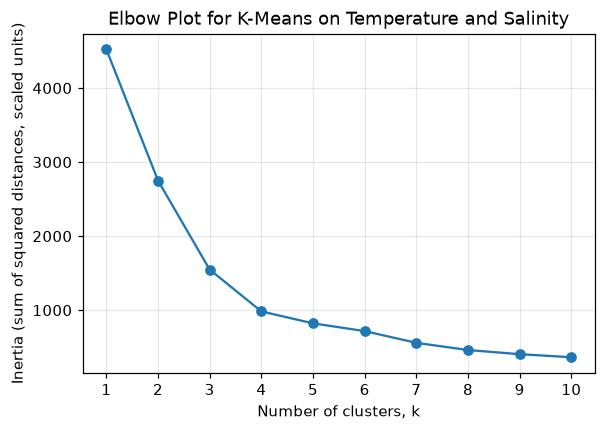

In [34]:
# Elbow plot
# Same approach as in class: run k-means for k = 1 to 10 and record the inertia (how spread out the points are around their cluster centers).
# Inertia always goes down as k goes up; we look for the "elbow" where adding more clusters stops making a big improvement.

inertias = []
ks = range(1, 11)

for k in ks:
    # Create a KMeans instance with k clusters
    # random_state makes the results the same every time you run it
    model = KMeans(n_clusters=k, n_init='auto', random_state=42)

    # Fit the model to the scaled temperature and salinity data
    model.fit(X_scaled)

    # Save the inertia for this k
    inertias.append(model.inertia_)

# Plot k vs inertia
plt.figure(figsize=(6, 4))
plt.plot(ks, inertias, '-o')
plt.xlabel('Number of clusters, k')
plt.ylabel('Inertia (sum of squared distances, scaled units)')
plt.title('Elbow Plot for K-Means on Temperature and Salinity')
plt.xticks(ks)
plt.grid(alpha=0.3)
plt.show()

In [35]:
# Fit the final k-means model
# Based on the elbow plot, we use 4 clusters.
N_CLUSTERS = 4

model = KMeans(n_clusters=N_CLUSTERS, n_init='auto', random_state=42)
model.fit(X_scaled)

# Each sample gets a cluster label (0, 1, 2, ...). Add it as a new column.
ts_df['Cluster'] = model.labels_

# The centroids (cluster centers) are in scaled units, so convert them back to °C and ppt with inverse_transform so they are easy to interpret.
centroids = scaler.inverse_transform(model.cluster_centers_)

# check the dimensions of the centroids: (number of clusters, number of features)
print(centroids.shape)

# Make a table of the cluster centers and how many samples are in each cluster
centroid_table = pd.DataFrame(centroids, columns=['Center temp (°C)', 'Center salinity (ppt)']).round(1)
centroid_table['n samples'] = ts_df['Cluster'].value_counts().sort_index().values
centroid_table.index.name = 'Cluster'
centroid_table

(4, 2)


,Center temp (°C),Center salinity (ppt),n samples
Cluster,,,
0,24.0,16.9,833
1,8.7,2.6,329
2,23.3,2.8,498
3,9.5,17.0,602


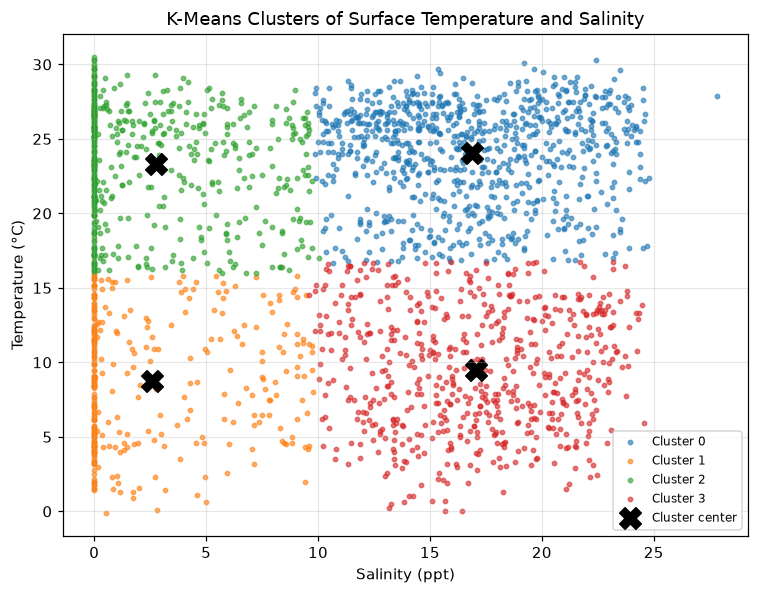

In [36]:
# FIGURE 18: The temperature-salinity clusters
# Each sample is colored by its cluster, and the cluster centers (centroids) are shown as black X's, like the centroid plot from class.

cluster_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

fig, ax = plt.subplots(figsize=(7, 5.5))
for c in range(N_CLUSTERS):
    g = ts_df[ts_df['Cluster'] == c]
    ax.scatter(g['Salinity_ppt'], g['Temperature_C'], s=8, alpha=0.6,
               color=cluster_colors[c], label=f'Cluster {c}')
# centroids: column 0 is temperature, column 1 is salinity
ax.scatter(centroids[:, 1], centroids[:, 0], s=200, color='black', marker='X',
           label='Cluster center')
ax.set_title('K-Means Clusters of Surface Temperature and Salinity')
ax.set_xlabel('Salinity (ppt)')
ax.set_ylabel('Temperature (°C)')
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [37]:
# Season and region of each cluster
# To help name each cluster, look at which seasons and regions its samples come 
# from. pd.crosstab counts samples for every cluster/season combination; normalize='index' turns the counts into the % of each cluster's samples.

season_order = ['Winter', 'Spring', 'Summer', 'Fall']
region_order = ['Upper Bay', 'Middle Bay', 'Lower Bay']

cluster_season = (pd.crosstab(ts_df['Cluster'], ts_df['Season'], normalize='index') * 100).round(0)
cluster_region = (pd.crosstab(ts_df['Cluster'], ts_df['Region'], normalize='index') * 100).round(0)

# join the two tables side by side (values are % of samples in each cluster)
cluster_description = pd.concat([cluster_season[season_order], cluster_region[region_order]], axis=1)
cluster_description

,Winter,Spring,Summer,Fall,Upper Bay,Middle Bay,Lower Bay
Cluster,,,,,,,
0,0.0,12.0,57.0,30.0,0.0,50.0,50.0
1,24.0,63.0,0.0,13.0,75.0,24.0,1.0
2,0.0,20.0,57.0,23.0,82.0,17.0,1.0
3,41.0,43.0,0.0,16.0,0.0,43.0,57.0


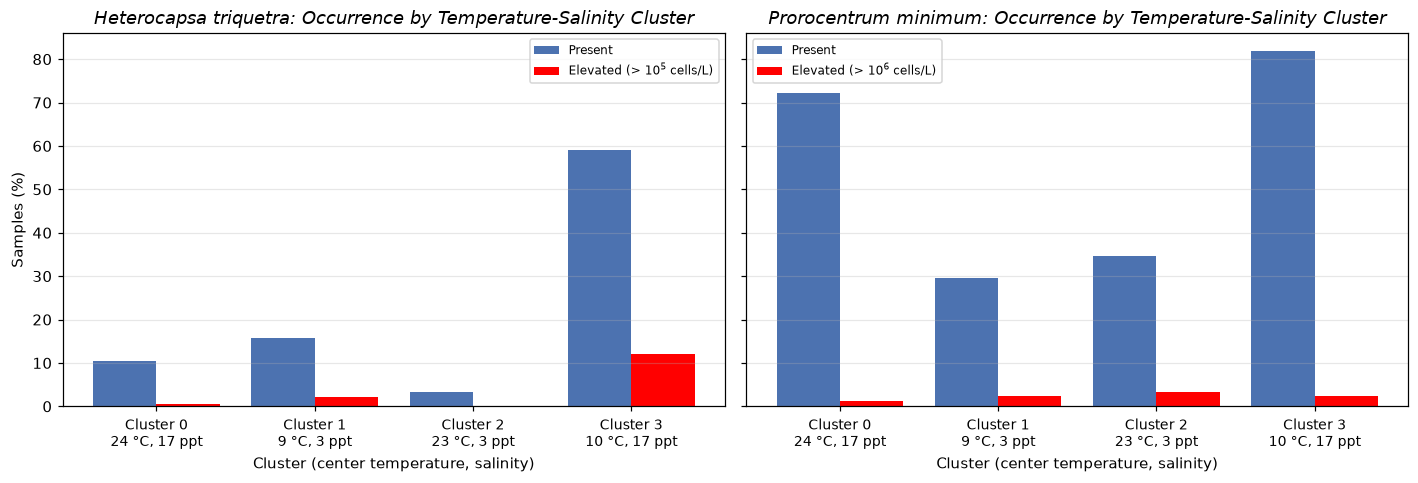

In [38]:
# FIGURE 19: How often each species is present / high in each cluster
# For each cluster we calculate the % of samples where each species was present and where it was high (same thresholds as Part 2). This shows which
# temperature-salinity regime each species prefers.

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
x = np.arange(N_CLUSTERS)
width = 0.4

# x-axis labels: cluster number plus its center temperature and salinity
cluster_labels = [f'Cluster {c}\n{centroids[c, 0]:.0f} °C, {centroids[c, 1]:.0f} ppt'
                  for c in range(N_CLUSTERS)]

for ax, (col, name) in zip(axes, SPECIES.items()):
    pct_present = []
    pct_high = []
    for c in range(N_CLUSTERS):
        g = ts_df[ts_df['Cluster'] == c]
        pct_present.append((g[col] > 0).mean() * 100)
        pct_high.append((g[col] > HIGH_THRESHOLD[col]).mean() * 100)
    ax.bar(x - width / 2, pct_present, width, color='#4c72b0', label='Present')
    ax.bar(x + width / 2, pct_high, width, color='red', label=HIGH_LABEL[col])
    ax.set_xticks(x)
    ax.set_xticklabels(cluster_labels, fontsize=9)
    ax.set_title(f'{name}: Occurrence by Temperature-Salinity Cluster', style='italic')
    ax.set_xlabel('Cluster (center temperature, salinity)')
    ax.grid(axis='y', alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel('Samples (%)')
plt.tight_layout()
plt.show()

**Part 3 results.** The elbow plot bends at k = 4, and the four clusters form clear regimes: cold and salty (~10 °C, 17 ppt; winter–spring, Middle and Lower Bay), cold and fresh (~9 °C, 3 ppt; winter–spring, mostly Upper Bay), warm and salty (~24 °C, 17 ppt; summer–fall, Middle and Lower Bay), and warm and fresh (~23 °C, 3 ppt; summer–fall, Upper Bay). *H. triquetra* is strongly tied to the cold-salty regime, where it was present in 59% of samples and elevated in 12%, far more than in any other regime. *P. minimum* is common in both salty regimes, but its elevated samples are spread across all four clusters (1–4% each), because they occur at intermediate conditions near the cluster boundaries. Part 2 describes the *P. minimum* window better than the clusters do.

## Part 4: Supervised classification with K-nearest neighbors (KNN)

A KNN classifier is trained to predict, from temperature, salinity, and month, (1) whether each species is present and (2) whether it is at high abundance. The data are split 80/20 into training and testing sets, k = 1-25 is tested, and the best k is chosen by balanced accuracy. Balanced accuracy is used because high-abundance samples are rare: a model that always guesses "no" would score 96–98% accuracy without finding anything.

In [39]:
# Features (inputs, X): the variables the model uses to make predictions.
# Month is included because each species has a strong seasonal cycle. 
# (Month is a number from 1-12, so the model treats December (12) and January (1) as far apart even though they are next to each other in
# time. ** could be a limitation for the model
knn_features = ['Temperature_C', 'Salinity_ppt', 'Month']

# Targets (outputs, y): what we want to predict. Each target is a yes/no (1/0) question. For each one we list: the abundance column and the
# threshold that counts as "yes".
knn_targets = {
    'H. triquetra present':                ('H_triquetra_cells_L', 0),
    'H. triquetra elevated (> 10^5 cells/L)': ('H_triquetra_cells_L', HIGH_THRESHOLD['H_triquetra_cells_L']),
    'P. minimum present':                  ('P_minimum_cells_L', 0),
    'P. minimum elevated (> 10^6 cells/L)':  ('P_minimum_cells_L', HIGH_THRESHOLD['P_minimum_cells_L']),
}

# Feature matrix (inputs) in an object named X, same as the iris example
X = ts_df[knn_features]
print('X shape (samples, features):', X.shape)

# Show how common "yes" is for each target. This matters: if "yes" is rare, a model can get high accuracy just by always guessing "no".
for target_name, (col, threshold) in knn_targets.items():
    y = (ts_df[col] > threshold).astype(int)    # 1 = yes, 0 = no
    print(f'{target_name}: {y.sum()} yes out of {len(y)} ({y.mean() * 100:.1f}%)')

X shape (samples, features): (2262, 3)
H. triquetra present: 513 yes out of 2262 (22.7%)
H. triquetra elevated (> 10^5 cells/L): 85 yes out of 2262 (3.8%)
P. minimum present: 1363 yes out of 2262 (60.3%)
P. minimum elevated (> 10^6 cells/L): 50 yes out of 2262 (2.2%)


In [40]:
# Split, scale, and try k = 1 to 25 for each target
# For each target we:
#   1. Split the data into training (80%) and testing (20%) sets, like class. stratify=y keeps the same % of "yes" samples in both sets, which is
#      important when "yes" is rare.
#   2. Scale the features. KNN finds the "nearest" samples by distance, so (like k-means) the features need to be on the same scale. The scaler
#      is fit on the TRAINING data only, then applied to the test data, so the test data stays truly "unseen".
#   3. Build a KNN model for each k and score it on the test data.
#
# Record two scores:
#   - accuracy: % of test samples predicted correctly (used in class)
#   - balanced accuracy: the average of the % of "yes" samples found and the % of "no" samples found. This is a fairer score when "yes" is rare,
#     because always guessing "no" only gets a balanced accuracy of 0.5.
# Use balanced accuracy to choose the best k.

k_range = range(1, 26)
knn_results = {}     # store everything for each target so we can use it later

for target_name, (col, threshold) in knn_targets.items():
    # Response vector (output or target) in an object named y
    y = (ts_df[col] > threshold).astype(int)

    # 1. split into training and testing sets (80:20), random_state=4 like class
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=4, stratify=y)

    # 2. scale: fit on training data, then transform both sets
    knn_scaler = StandardScaler()
    X_train_scaled = knn_scaler.fit_transform(X_train)
    X_test_scaled = knn_scaler.transform(X_test)

    # 3. try each value of k and record the test scores
    accuracy_list = []
    balanced_list = []
    for k in k_range:
        knn = KNeighborsClassifier(n_neighbors=k)
        knn.fit(X_train_scaled, y_train)
        y_pred = knn.predict(X_test_scaled)
        accuracy_list.append(metrics.accuracy_score(y_test, y_pred))
        balanced_list.append(metrics.balanced_accuracy_score(y_test, y_pred))

    # the best k is the one with the highest balanced accuracy
    best_k = list(k_range)[int(np.argmax(balanced_list))]

    knn_results[target_name] = {
        'X_train': X_train_scaled, 'X_test': X_test_scaled,
        'y_train': y_train, 'y_test': y_test, 'scaler': knn_scaler,
        'accuracy': accuracy_list, 'balanced': balanced_list, 'best_k': best_k,
    }
    print(f'{target_name}: best k = {best_k}')

H. triquetra present: best k = 9
H. triquetra elevated (> 10^5 cells/L): best k = 1
P. minimum present: best k = 21
P. minimum elevated (> 10^6 cells/L): best k = 1


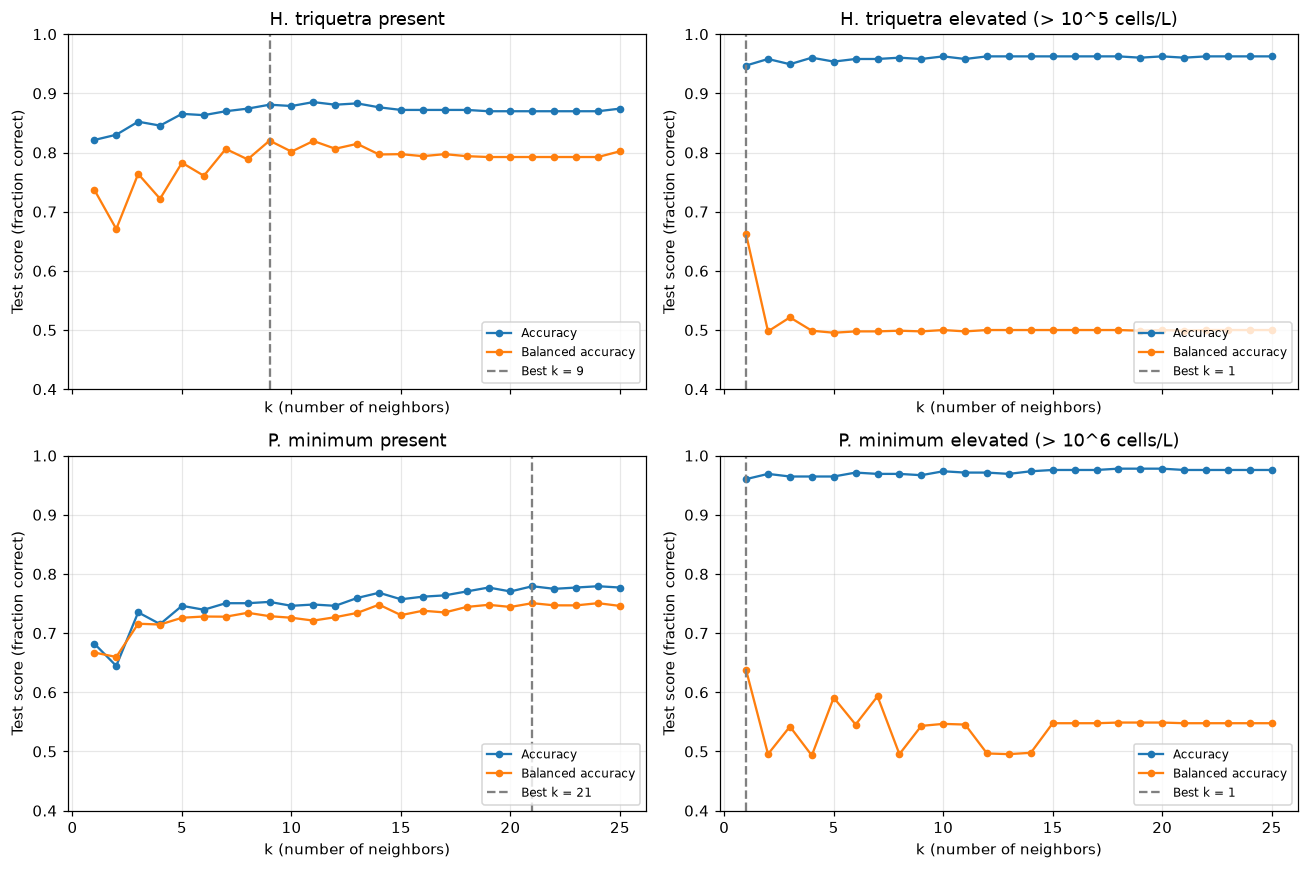

In [41]:
# FIGURE 20: Model score for each value of k
# Like the accuracy-vs-k plot from class, with balanced accuracy added. The dashed line marks the best k for each target.

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)

for ax, (target_name, res) in zip(axes.flatten(), knn_results.items()):
    ax.plot(k_range, res['accuracy'], 'o-', markersize=4, label='Accuracy')
    ax.plot(k_range, res['balanced'], 'o-', markersize=4, label='Balanced accuracy')
    ax.axvline(res['best_k'], color='grey', linestyle='--', label=f"Best k = {res['best_k']}")
    ax.set_title(target_name)
    ax.set_xlabel('k (number of neighbors)')
    ax.set_ylabel('Test score (fraction correct)')
    ax.set_ylim(0.4, 1.0)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='lower right')

plt.tight_layout()
plt.show()

In [42]:
# Final model for each target, using the best k
# Scores (all calculated on the TEST data the model has never seen):
#   - Accuracy: % of test samples predicted correctly
#   - Baseline accuracy: the accuracy you would get by always guessing the most common answer. A useful model should beat this.
#   - Recall: of the samples that were really "yes", the % the model found
#   - Precision: of the samples the model said were "yes", the % that really were
#   - Balanced accuracy: average of the recall for "yes" and for "no"

rows = []
for target_name, res in knn_results.items():
    knn = KNeighborsClassifier(n_neighbors=res['best_k'])
    knn.fit(res['X_train'], res['y_train'])
    y_pred = knn.predict(res['X_test'])
    res['model'] = knn          # save the fitted model
    res['y_pred'] = y_pred      # save the predictions for the next figure

    y_test = res['y_test']
    baseline = max(y_test.mean(), 1 - y_test.mean())   # always guess the most common class
    rows.append({
        'Target': target_name,
        'Best k': res['best_k'],
        'Accuracy': round(metrics.accuracy_score(y_test, y_pred), 2),
        'Baseline accuracy': round(baseline, 2),
        'Recall': round(metrics.recall_score(y_test, y_pred, zero_division=0), 2),
        'Precision': round(metrics.precision_score(y_test, y_pred, zero_division=0), 2),
        'Balanced accuracy': round(metrics.balanced_accuracy_score(y_test, y_pred), 2),
    })

knn_summary = pd.DataFrame(rows)
knn_summary

,Target,Best k,Accuracy,Baseline accuracy,Recall,Precision,Balanced accuracy
0,H. triquetra present,9,0.88,0.77,0.71,0.75,0.82
1,H. triquetra elevated (> 10^5 cells/L),1,0.95,0.96,0.35,0.32,0.66
2,P. minimum present,21,0.78,0.60,0.89,0.78,0.75
3,P. minimum elevated (> 10^6 cells/L),1,0.96,0.98,0.30,0.21,0.64


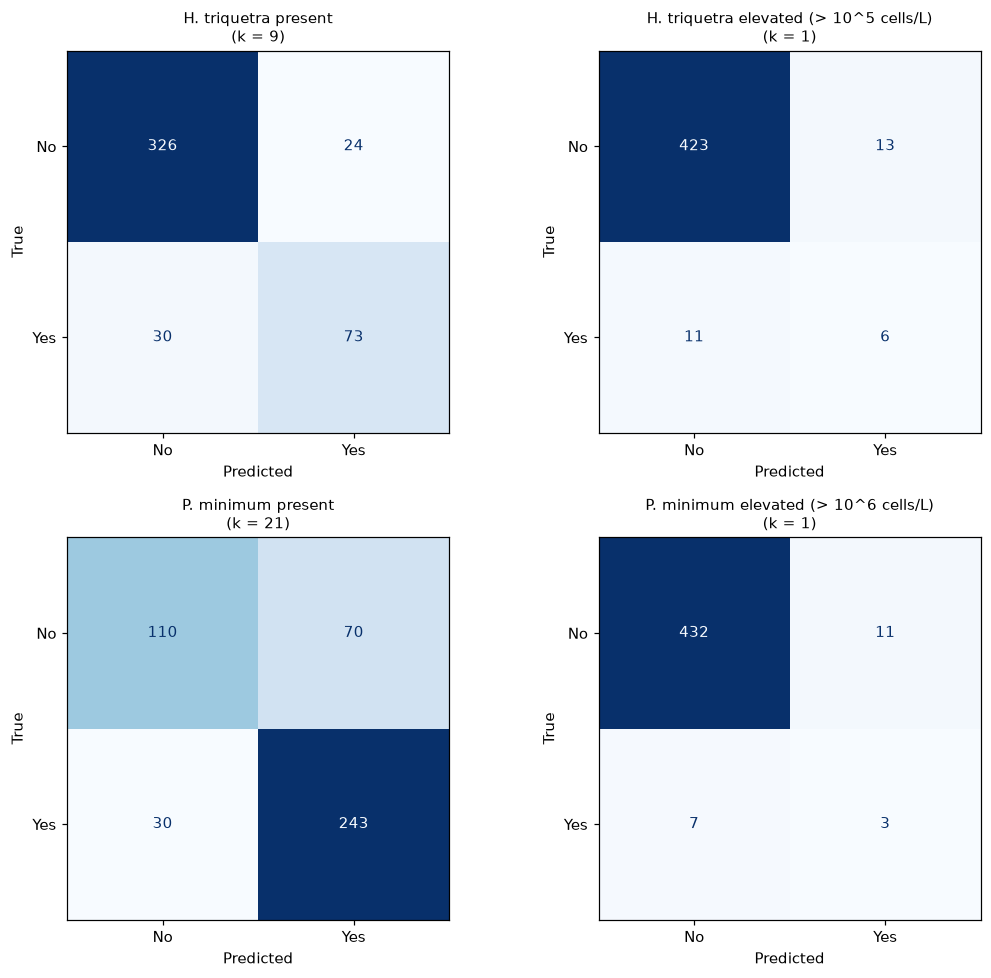

In [43]:
# FIGURE 21: Confusion matrices
# A confusion matrix compares the true answers (rows) with the model's predictions (columns) for the test data:
#   top-left  = correctly predicted "no"     top-right = false alarms
#   bottom-left = missed "yes" samples        bottom-right = correctly found "yes"

fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for ax, (target_name, res) in zip(axes.flatten(), knn_results.items()):
    metrics.ConfusionMatrixDisplay.from_predictions(
        res['y_test'], res['y_pred'], display_labels=['No', 'Yes'],
        cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f"{target_name}\n(k = {res['best_k']})", fontsize=10)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.tight_layout()
plt.show()

In [44]:
# Use the presence models to make predictions for new conditions
# Like the iris example, we give the model "new" data it has not seen and ask for a prediction. Each row is [temperature (°C), salinity (ppt), month].
x_new = pd.DataFrame([[6, 16, 2],      # cold, salty water in February
                      [25, 5, 8],      # warm, fresh water in August
                      [16, 10, 5]],    # mild, brackish water in May
                     columns=knn_features)

classes = {0: 'absent', 1: 'present'}

for target_name in ['H. triquetra present', 'P. minimum present']:
    res = knn_results[target_name]
    # new data must be scaled the same way as the training data
    x_new_scaled = res['scaler'].transform(x_new)
    y_predict = res['model'].predict(x_new_scaled)
    print(target_name.replace(' present', '') + ':')
    for i in range(len(x_new)):
        t, s, m = x_new.iloc[i]
        print(f'   {t:.0f} °C, {s:.0f} ppt, month {m:.0f} -> predicted {classes[y_predict[i]]}')

H. triquetra:
   6 °C, 16 ppt, month 2 -> predicted present
   25 °C, 5 ppt, month 8 -> predicted absent
   16 °C, 10 ppt, month 5 -> predicted absent
P. minimum:
   6 °C, 16 ppt, month 2 -> predicted present
   25 °C, 5 ppt, month 8 -> predicted absent
   16 °C, 10 ppt, month 5 -> predicted present


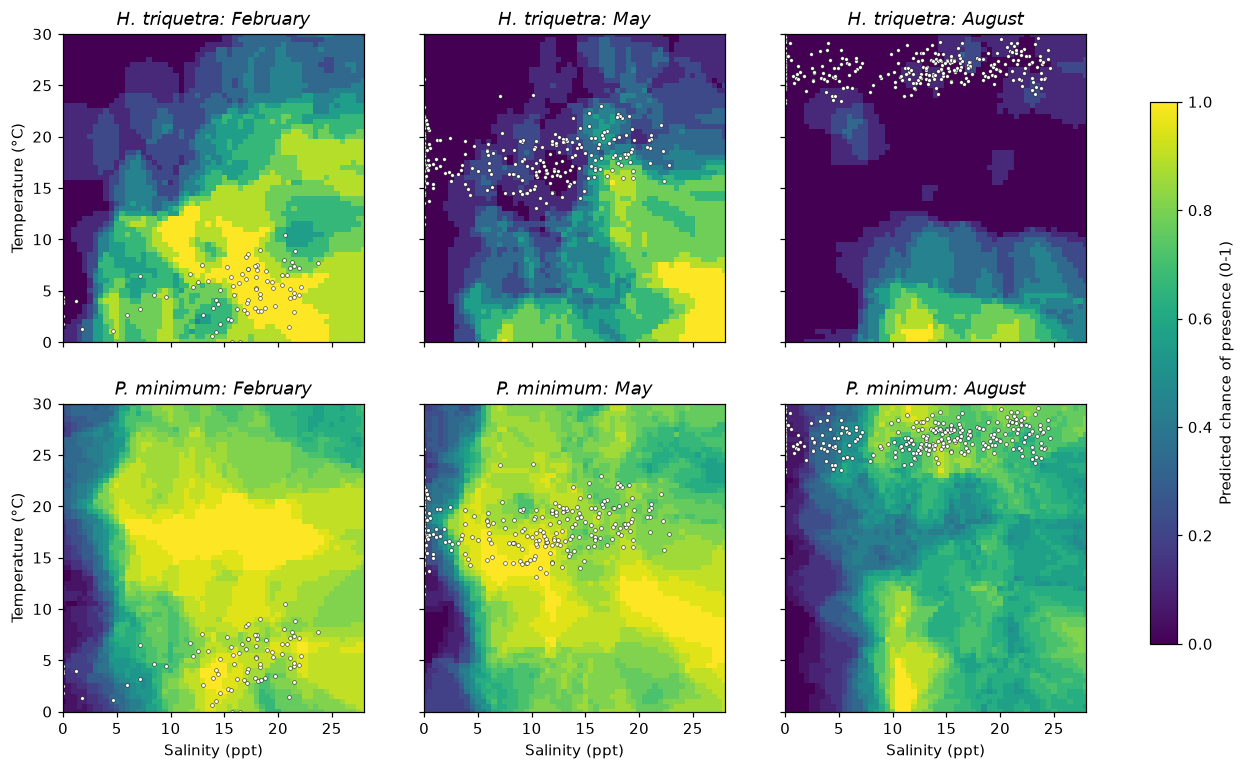

In [45]:
# FIGURE 22: Predicted chance of presence across temperature and salinity
# We ask each presence model for a prediction at every combination of temperature (0-30 °C) and salinity (0-28 ppt) for three months.
# predict_proba gives the fraction of the k nearest neighbors where the species was present, i.e., the model's estimated chance of presence.
# Note: some combinations (e.g., 28 °C in February) never happen in the Bay, so the model is guessing there; focus on the conditions that actually occur.

temps = np.arange(0, 30.5, 0.5)
sals = np.arange(0, 28.5, 0.5)
T_grid, S_grid = np.meshgrid(temps, sals)    # every temperature/salinity combination
months_to_show = {2: 'February', 5: 'May', 8: 'August'}

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)

for row, target_name in enumerate(['H. triquetra present', 'P. minimum present']):
    res = knn_results[target_name]
    for col_i, (month, month_name) in enumerate(months_to_show.items()):
        # build a table of new data: one row per grid point, all in this month
        grid = pd.DataFrame({'Temperature_C': T_grid.ravel(),
                             'Salinity_ppt': S_grid.ravel(),
                             'Month': month})
        # scale, then get the probability of "present" (column 1)
        prob = res['model'].predict_proba(res['scaler'].transform(grid))[:, 1]
        prob = prob.reshape(T_grid.shape)

        ax = axes[row, col_i]
        im = ax.pcolormesh(S_grid, T_grid, prob, cmap='viridis', vmin=0, vmax=1, shading='auto')
        # overlay the real samples from that month so we can see which conditions occur
        real = ts_df[ts_df['Month'] == month]
        ax.scatter(real['Salinity_ppt'], real['Temperature_C'], s=6, color='white',
                   edgecolor='k', linewidth=0.3)
        ax.set_title(f"{target_name.replace(' present', '')}: {month_name}", style='italic')
        ax.set_xlim(0, 28)
        ax.set_ylim(0, 30)
        if row == 1:
            ax.set_xlabel('Salinity (ppt)')
        if col_i == 0:
            ax.set_ylabel('Temperature (°C)')

cbar = fig.colorbar(im, ax=axes, shrink=0.8)
cbar.set_label('Predicted chance of presence (0-1)')
plt.show()

**Part 4 results.** Presence is predictable. The *H. triquetra* model was 88% accurate (vs. 77% from always guessing "absent") and found 71% of real presences. The *P. minimum* model was 78% accurate (vs. 60%) and found 89% of real presences. High abundance was not predictable: the models found only about a third of elevated *H. triquetra* (recall 0.35) and elevated *P. minimum* (recall 0.30), and most "yes" predictions were false alarms. The best k for both was 1, meaning the model was copying the single nearest sample rather than finding a real pattern.

## Summary

Temperature, salinity, and season clearly separate the habitats of the two species. *H. triquetra* is a cold-water (below ~10–12 °C), moderately salty (~11–19 ppt) winter–spring species of the Middle and Lower Bay. *P. minimum* is found year-round in brackish to salty water and reaches elevated levels mainly in spring at ~8–20 °C and ~5–16 ppt, with true blooms concentrated in the Middle Bay (CB4.3C) in April and May. These conditions predict **where and when each species can occur** well, but not **when it reaches high abundance**, which likely depends on factors not included here, such as nutrients, light, and water-column stratification.

**Limitations:** counting methods differ between the Maryland and Virginia programs and over time; Upper and Middle Bay phytoplankton data end in 2019; phytoplankton samples are composites while temperature and salinity are surface point measurements; both species rarely reached published bloom thresholds in these samples (4 *H. triquetra* and 9 *P. minimum* blooms); and month is treated as a number (1–12) in the KNN model, so December and January appear far apart.

**References**
- Litaker, R.W., Warner, V.E., Rhyne, C., Duke, C.S., Kenney, B.E., Ramus, J., & Tester, P.A. (2002). Effect of diel and interday variations in light on the cell division pattern and in situ growth rates of the bloom-forming dinoflagellate *Heterocapsa triquetra*. *Marine Ecology Progress Series*, 232, 63–74.
- Tango, P.J., Magnien, R., Butler, W., Luckett, C., Luckenbach, M., Lacouture, R., & Poukish, C. (2005). Impacts and potential effects due to *Prorocentrum minimum* blooms in Chesapeake Bay. *Harmful Algae*, 4(3), 525–531. https://doi.org/10.1016/j.hal.2004.08.014